<a href="https://colab.research.google.com/github/joelnin-star/PI1-Bike-Sharing-Diseno-Experimental/blob/main/LAB_D10_Joel_Nino_de_Guzman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANALÍTICA EMPRESARIAL INTEGRADA
## LABORATORIO DIRIGIDO N.° 10 — Pronóstico de demanda

**Semana 10 · TECSUP 2026-II**
**Docente:** PILAR ROCIO SAYAN MEJIA
**Dataset real:** Online Retail II — UCI Machine Learning Repository (ID 502)




- Estudiante:
* Joel Ronald Niño de Guzmán Rodríguez
* Renzo  Espinza Tuesta
* Diego Yeferson Quispe Huamani
- Sección: C28 6to A-L - L
- Docente: Pilar Rocío Sayán Mejía
- Curso: Analítica Empresarial Integrada



# 1. Pregunta de negocio

**¿Cuántas unidades debería planificar la empresa para las próximas semanas, qué riesgo asume si el pronóstico se equivoca y conviene adoptar el modelo?**

Se distinguen cuatro pasos que no deben confundirse:
1. **Pronóstico de ventas:** estimación de las ventas semanales.
2. **Política de cantidad:** regla que convierte el pronóstico en una cantidad objetivo semanal (pronóstico + colchón).
3. **Evaluación económica:** costo de los excedentes y faltantes que produce esa política.
4. **Decisión de adopción:** usar, mantener en evaluación o no usar el modelo, según su resultado frente al baseline.

### Diseño del laboratorio
| Elemento | Definición |
|---|---|
| Unidad temporal | Semana de lunes a domingo, identificada por la fecha del lunes |
| Semanas válidas | Solo semanas completas según la cobertura del archivo |
| Variable objetivo | Unidades vendidas (registradas) por semana de un SKU del Reino Unido |
| Test final | Últimas 8 semanas completas; se evalúa una sola vez |
| Selección del SKU | Criterios calculados solo antes del test |
| Validación | Backtesting rolling-origin con horizonte de 8 semanas dentro del entrenamiento |
| Modelos | Naïve, Naïve estacional (m = 4) y Exponential Smoothing |
| Regla de selección (única) | Candidatos con costo promedio ≤ mínimo × 1,01 (incluye exactamente el 1 %); si el mínimo es 0, solo empatan los costos 0. Desempate: menor MAE, menor desviación del costo, menor complejidad |
| Política de colchón | Multiplicador 0; 0,5; 1 o 1,5 × MAE previo; el MAE previo de cada origen usa solo errores anteriores a ese origen |

## Actividad 1 — Conceptos aplicados
| Concepto | Definición y ejemplo |
|---|---|
| Serie temporal | Observaciones ordenadas por fecha. Las ventas de una semana pueden depender de semanas anteriores; barajar filas mezcla pasado y futuro. |
| Semana completa | Bloque lunes–domingo cubierto por el archivo. Si la carga comienza un martes, esa semana contiene menos días observados y no es comparable. |
| Tendencia y estacionalidad | La tendencia es un cambio sostenido del nivel; la estacionalidad es una repetición con periodo estable. Subidas y bajadas aisladas no prueban un ciclo. |
| Naïve y Naïve estacional | Referencias simples: repetir la última venta o el último ciclo de cuatro semanas. Si un método más complejo no las supera, su complejidad no está justificada con esta evidencia. |
| Exponential Smoothing | Estima nivel y, según su especificación, tendencia y estacionalidad, dando pesos que disminuyen sobre el pasado. Añadir componentes puede ajustar ruido y empeorar la predicción. |
| Train, validación y test | El entrenamiento ajusta; la validación elige modelo y política; el test verifica la decisión ya fijada. Elegir después de mirar el test lo convierte en otra validación. |
| Rolling-origin | Repite pronósticos desde distintos cortes históricos con horizonte de ocho semanas. Permite comprobar si el método funciona en más de un periodo. |
| MAE, RMSE y WAPE | MAE: error absoluto promedio en unidades. RMSE: también en unidades, con mayor penalización de errores grandes. WAPE: error absoluto total dividido por ventas totales, expresado como proporción. |
| Costo asimétrico | Faltar y excederse tienen consecuencias distintas. Con los costos base, faltar 20 unidades cuesta £30 y excederse 20 cuesta £8. |
| Pronóstico, cantidad y costo | El pronóstico estima ventas; la política suma un colchón; el costo evalúa faltantes y sobrantes. La cantidad objetivo no es una compra: faltan inventario utilizable y recepciones oportunas. |


In [87]:
# Dependencias para Colab. No se instala nada si ya está disponible.
import importlib.util, subprocess, sys
requeridas = {"numpy":"numpy", "pandas":"pandas", "statsmodels":"statsmodels", "plotly":"plotly", "sklearn":"scikit-learn", "openpyxl":"openpyxl"}
faltantes = [paquete for modulo, paquete in requeridas.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Dependencias disponibles.")


Dependencias disponibles.


In [88]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import sklearn
import statsmodels

from IPython.display import display, Markdown
import hashlib, pathlib, json
import matplotlib.pyplot as plt
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# No se ocultan advertencias globalmente: las de cada ajuste se registran y se revisan al final.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
VERSIONES = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
             "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__}
print("Versiones:", VERSIONES)

def mostrar_figura(fig):
    # PNG autónomo: visible en GitHub, Colab y sin conexión.
    from io import BytesIO
    from IPython.display import Image
    f, ax = plt.subplots(figsize=(10,4))
    barras=[t for t in fig.data if t.type=="bar"]
    if barras:
        categorias=list(dict.fromkeys(str(x) for t in barras for x in t.x))
        posiciones=np.arange(len(categorias));ancho=0.8/len(barras)
        for j,t in enumerate(barras):
            valores={str(x):v for x,v in zip(t.x,t.y)}
            ax.bar(posiciones+(j-(len(barras)-1)/2)*ancho,[valores.get(x,0) for x in categorias],width=ancho,label=t.name)
        ax.set_xticks(posiciones,categorias)
    elif all(t.type=="box" for t in fig.data):
        grupos={}
        for t in fig.data:
            for x,y in zip(t.x,t.y):grupos.setdefault(str(x),[]).append(y)
        ax.boxplot(list(grupos.values()),tick_labels=list(grupos))
        for j,ys in enumerate(grupos.values(),1):ax.scatter([j]*len(ys),ys,s=24,zorder=3)
    else:
        for t in fig.data:
            xs=list(t.x)
            if xs and isinstance(xs[0],str) and len(xs[0])>=10 and xs[0][4:5]=="-":xs=pd.to_datetime(xs)
            ax.plot(xs,list(t.y),label=t.name,linewidth=1.3)
        f.autofmt_xdate()
    ax.set_title(fig.layout.title.text or "")
    ax.set_xlabel(fig.layout.xaxis.title.text or "")
    ax.set_ylabel(fig.layout.yaxis.title.text or "")
    ax.grid(alpha=.2)
    handles,labels=ax.get_legend_handles_labels()
    if handles:ax.legend(fontsize=8)
    f.tight_layout();buffer=BytesIO();f.savefig(buffer,format="png",dpi=130,bbox_inches="tight")
    display(Image(data=buffer.getvalue()));plt.close(f)


Versiones: {'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0', 'scikit-learn': '1.6.1'}


# 2. Datos y procedencia

Se leen las dos hojas del Excel de Online Retail II. Si `online_retail_II.xlsx` está en la carpeta de trabajo, se utiliza esa copia; si no, se descarga el ZIP oficial de UCI y se extrae el Excel en memoria. Si la descarga falla, se puede subir manualmente ese Excel a la carpeta de archivos de Colab y volver a ejecutar la celda.

Se registran las hojas, las dimensiones, las fechas, las versiones y el SHA-256 para identificar la copia utilizada. Los resultados de Exponential Smoothing pueden variar entre entornos; las conclusiones de esta entrega se sustentan en las salidas que conserva este notebook.

In [46]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
URL_UCI = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
local = pathlib.Path("online_retail_II.xlsx")
if local.exists():
    contenido_excel = local.read_bytes()
    fuente = "Copia local del Excel del ZIP oficial UCI ID 502"
else:
    with urlopen(URL_UCI, timeout=120) as respuesta:
        blob = respuesta.read()
    with ZipFile(BytesIO(blob)) as z:
        nombres = [x for x in z.namelist() if x.lower().endswith(".xlsx")]
        assert len(nombres) == 1
        contenido_excel = z.read(nombres[0])
    fuente = "ZIP oficial de UCI ID 502"
hojas = pd.read_excel(BytesIO(contenido_excel), sheet_name=None)
hojas_leidas = list(hojas)
assert hojas_leidas == ["Year 2009-2010", "Year 2010-2011"], hojas_leidas
print("Filas por hoja:", {k: len(v) for k,v in hojas.items()})
df = pd.concat(hojas.values(), ignore_index=True)
SHA256_DATOS = hashlib.sha256(contenido_excel).hexdigest()
fechas_raw = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Origen:", URL_UCI)
print("Fuente utilizada:", fuente)
print("SHA-256 del Excel:", SHA256_DATOS)
print("Hojas:", hojas_leidas, "· Dimensión:", df.shape)
print("Rango:", fechas_raw.min(), "→", fechas_raw.max())
print("Ejecución UTC:", pd.Timestamp.now(tz="UTC").isoformat())
print("Versiones:", VERSIONES)
display(df.head())
del hojas, contenido_excel


Filas por hoja: {'Year 2009-2010': 525461, 'Year 2010-2011': 541910}
Origen: https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip
Fuente utilizada: ZIP oficial de UCI ID 502
SHA-256 del Excel: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980
Hojas: ['Year 2009-2010', 'Year 2010-2011'] · Dimensión: (1067371, 8)
Rango: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Ejecución UTC: 2026-10-26T03:01:27.764805+00:00
Versiones: {'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0', 'scikit-learn': '1.6.1'}


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [47]:
def find_col(columns, candidates):
    normalized = {str(c).lower().replace(" ", "").replace("_", ""): c for c in columns}
    for cand in candidates:
        key = cand.lower().replace(" ", "").replace("_", "")
        if key in normalized:
            return normalized[key]
    return None

mapping = {
    "InvoiceNo": find_col(df.columns, ["InvoiceNo", "Invoice"]),
    "StockCode": find_col(df.columns, ["StockCode"]),
    "Description": find_col(df.columns, ["Description"]),
    "Quantity": find_col(df.columns, ["Quantity"]),
    "InvoiceDate": find_col(df.columns, ["InvoiceDate"]),
    "UnitPrice": find_col(df.columns, ["UnitPrice", "Price"]),
    "CustomerID": find_col(df.columns, ["Customer ID", "CustomerID"]),
    "Country": find_col(df.columns, ["Country"]),
}
faltan = [k for k, v in mapping.items() if v is None and k not in ("Description", "CustomerID")]
if faltan:
    raise ValueError(f"No se identificaron columnas obligatorias: {faltan}")
df = df.rename(columns={v: k for k, v in mapping.items() if v is not None})
print(mapping)

{'InvoiceNo': 'Invoice', 'StockCode': 'StockCode', 'Description': 'Description', 'Quantity': 'Quantity', 'InvoiceDate': 'InvoiceDate', 'UnitPrice': 'Price', 'CustomerID': 'Customer ID', 'Country': 'Country'}


# 3. Control de calidad

Los `StockCode` nulos se descartan **antes** de convertir a texto; de lo contrario, la ausencia se convertiría en un producto llamado «nan».

In [48]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
print("StockCode nulos descartados:", int(df["StockCode"].isna().sum()))
df = df[df["StockCode"].notna()].copy()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df = df[df["StockCode"] != ""]
cancel = df["InvoiceNo"].astype(str).str.upper().str.startswith("C")

print("Fecha mínima:", df["InvoiceDate"].min(), "·", df["InvoiceDate"].min().day_name())
print("Fecha máxima:", df["InvoiceDate"].max(), "·", df["InvoiceDate"].max().day_name())
print("Cancelaciones:", int(cancel.sum()))
print("Quantity <= 0:", int((df["Quantity"] <= 0).sum()))
print("UnitPrice <= 0:", int((df["UnitPrice"] <= 0).sum()))
print("Fechas nulas:", int(df["InvoiceDate"].isna().sum()))

clean = df.loc[(~cancel) & df["InvoiceDate"].notna() & (df["Quantity"] > 0) &
               (df["UnitPrice"] > 0) & df["Country"].notna()].copy()
uk = clean[clean["Country"].astype(str).str.upper().eq("UNITED KINGDOM")].copy()
print("Filas válidas UK:", len(uk), "· SKUs UK:", uk["StockCode"].nunique())
print("Duplicados exactos detectados (se conservan para seguir la guía):", int(df.duplicated().sum()))
print("CustomerID nulos (no se excluyen para pronosticar ventas):", int(df["CustomerID"].isna().sum()))
assert len(df) == 1067371, "Revisar procedencia y hojas si cambia la dimensión"


StockCode nulos descartados: 0
Fecha mínima: 2009-12-01 07:45:00 · Tuesday
Fecha máxima: 2011-12-09 12:50:00 · Friday
Cancelaciones: 19494
Quantity <= 0: 22950
UnitPrice <= 0: 6207
Fechas nulas: 0
Filas válidas UK: 958501 · SKUs UK: 4905
Duplicados exactos detectados (se conservan para seguir la guía): 34335
CustomerID nulos (no se excluyen para pronosticar ventas): 243007


### Pregunta 1
¿Por qué no sería correcto sumar directamente `Quantity` sin eliminar cancelaciones y cantidades no positivas?

**Respuesta:**

Se mezclarían ventas con devoluciones, anulaciones o ajustes. Una devolución de 10 no significa que existiera demanda negativa esa semana. Para comparar ventas positivas sigo el filtro de la guía: sin facturas C, cantidades y precios positivos, fecha y país válidos. Esto no reconstruye demanda perdida ni inventario.


# 4. Semanas completas y partición temporal

Las semanas van de **lunes a domingo** y se identifican por la fecha del lunes. Una semana es **completa** solo si el archivo cubre sus siete días: se excluyen la primera semana si el archivo no empieza en lunes y la última si no termina en domingo. Las **últimas 8 semanas completas** se reservan como test final.

Algunas semanas no tienen **ninguna venta registrada** en los datos filtrados. El cierre de la tienda es una **posible explicación no verificada**: los datos no lo confirman.

In [49]:
def lunes(fechas):
    fechas = pd.to_datetime(fechas)
    return fechas.dt.normalize() - pd.to_timedelta(fechas.dt.weekday, unit="D")

uk["week"] = lunes(uk["InvoiceDate"])
inicio_archivo, fin_archivo = df["InvoiceDate"].min(), df["InvoiceDate"].max()
lunes_inicio = inicio_archivo.normalize() - pd.Timedelta(days=inicio_archivo.weekday())
lunes_fin = fin_archivo.normalize() - pd.Timedelta(days=fin_archivo.weekday())
primera_completa = lunes_inicio if inicio_archivo.weekday() == 0 else lunes_inicio + pd.Timedelta(weeks=1)
ultima_completa = lunes_fin if fin_archivo.weekday() == 6 else lunes_fin - pd.Timedelta(weeks=1)

semanas = pd.date_range(primera_completa, ultima_completa, freq="W-MON")
TEST_H = 8
semanas_test = semanas[-TEST_H:]
semanas_train = semanas[:-TEST_H]

registros = uk.groupby("week").size().reindex(semanas, fill_value=0)
semanas_sin_registro = registros[registros == 0].index

print("Semanas excluidas por incompletas:", lunes_inicio.date(), "y", lunes_fin.date())
print("Semanas completas:", len(semanas), "·", semanas[0].date(), "→", semanas[-1].date())
print("Entrenamiento:", len(semanas_train), "semanas ·", semanas_train[0].date(), "→", semanas_train[-1].date())
print("Test final:", len(semanas_test), "semanas ·", semanas_test[0].date(), "→", semanas_test[-1].date())
print("Semanas sin ventas registradas en los datos filtrados (cierre: explicación posible no verificada):",
      [d.date() for d in semanas_sin_registro])

Semanas excluidas por incompletas: 2009-11-30 y 2011-12-05
Semanas completas: 104 · 2009-12-07 → 2011-11-28
Entrenamiento: 96 semanas · 2009-12-07 → 2011-10-03
Test final: 8 semanas · 2011-10-10 → 2011-11-28
Semanas sin ventas registradas en los datos filtrados (cierre: explicación posible no verificada): [datetime.date(2009, 12, 28), datetime.date(2010, 12, 27)]


### Pregunta 2
¿Por qué una partición aleatoria con `train_test_split` sería incorrecta en este problema?

**Respuesta:**

Con una partición aleatoria el entrenamiento podría contener semanas posteriores a las que intenta pronosticar. Esa información todavía no existiría al planificar. Se conservan las últimas ocho semanas completas para test y se eligen modelo y colchón con cortes anteriores.


# 5. Selección reproducible del producto (solo con el entrenamiento)

Criterios, calculados **exclusivamente con las semanas de entrenamiento**:
1. **Periodo con ventas registradas cercano al entrenamiento completo:** primera venta dentro de las **4 primeras** semanas y última venta dentro de las **4 últimas**. El criterio tolera hasta 3 semanas iniciales o finales sin ventas, que luego se completan con cero aunque podrían corresponder a un periodo sin disponibilidad. **No verifica inventario.**
2. **Cobertura:** ventas registradas en al menos el 90 % de las semanas de entrenamiento con algún registro en la tienda.
3. Entre los elegibles, el de **mayor cantidad de unidades**; desempate por más semanas con ventas.

Se comprueba que haya al menos un producto elegible (y al menos dos para el Reto 3).

In [50]:
uk_train = uk[uk["week"].isin(semanas_train)]
semanas_con_registro_train = [w for w in semanas_train if w not in set(semanas_sin_registro)]

cobertura = (uk_train.groupby(["StockCode", "week"])["Quantity"].sum().reset_index()
             .groupby("StockCode")
             .agg(semanas_con_venta=("week", "nunique"), unidades=("Quantity", "sum"),
                  primera_venta=("week", "min"), ultima_venta=("week", "max"))
             .reset_index())
cobertura["cobertura"] = cobertura["semanas_con_venta"] / len(semanas_con_registro_train)
elegibles = cobertura[
    (cobertura["primera_venta"] <= semanas_train[3]) &      # dentro de las 4 primeras semanas
    (cobertura["ultima_venta"] >= semanas_train[-4]) &      # dentro de las 4 últimas semanas
    (cobertura["cobertura"] >= 0.90)
].sort_values(["unidades", "semanas_con_venta"], ascending=False).reset_index(drop=True)

if len(elegibles) == 0:
    raise ValueError("Ningún SKU cumple los criterios: revise la carga y la limpieza antes de continuar.")
print("SKUs elegibles:", len(elegibles), "· suficientes para el Reto 3:", len(elegibles) >= 2)
SKU = elegibles.loc[0, "StockCode"]
desc = uk_train.loc[uk_train["StockCode"] == SKU, "Description"].dropna().astype(str).mode().iloc[0]
print("SKU seleccionado:", SKU, "·", desc)
display(elegibles.head(5))


SKUs elegibles: 389 · suficientes para el Reto 3: True
SKU seleccionado: 84077 · WORLD WAR 2 GLIDERS ASSTD DESIGNS


,StockCode,semanas_con_venta,unidades,primera_venta,ultima_venta,cobertura
0,84077,93,88273,2009-12-07,2011-10-03,0.989362
1,85123A,94,80903,2009-12-07,2011-10-03,1.000000
2,85099B,94,79134,2009-12-07,2011-10-03,1.000000
3,21212,94,67878,2009-12-07,2011-10-03,1.000000
4,17003,88,67514,2009-12-07,2011-10-03,0.936170


# 6. Serie semanal de ventas registradas

**Qué representa un cero.** Un cero indica que **no hay ventas registradas** del SKU en esa semana dentro de los datos filtrados. Los datos no permiten distinguir entre:
- **disponibilidad de inventario** con demanda nula;
- **demanda no satisfecha** por falta de inventario (no queda registrada);
- **ausencia de registros** (por ejemplo, semanas sin ninguna venta registrada en la tienda).

Completar con cero es un **supuesto sobre las ventas observadas**: no demuestra demanda cero ni disponibilidad continua. Por eso el laboratorio pronostica **ventas registradas**, que solo aproximan la demanda.

In [51]:
serie = (uk[uk["StockCode"] == SKU].groupby("week")["Quantity"].sum()
         .reindex(semanas, fill_value=0).astype(float))
serie.name = "unidades"
train = serie.loc[semanas_train]
test = serie.loc[semanas_test]

ceros = serie[serie == 0].index
print("Semanas de la serie:", len(serie), "· semanas sin ventas registradas del SKU:", len(ceros))
print("  coinciden con semanas sin ningún registro en la tienda:", [d.date() for d in ceros if d in set(semanas_sin_registro)])
print("  semanas con registros en la tienda pero sin ventas del SKU:", [d.date() for d in ceros if d not in set(semanas_sin_registro)])
print("Unidades en entrenamiento:", int(train.sum()))

Semanas de la serie: 104 · semanas sin ventas registradas del SKU: 3
  coinciden con semanas sin ningún registro en la tienda: [datetime.date(2009, 12, 28), datetime.date(2010, 12, 27)]
  semanas con registros en la tienda pero sin ventas del SKU: [datetime.date(2011, 1, 17)]
Unidades en entrenamiento: 88273


# 7. Exploración (solo con el entrenamiento)

La exploración que orienta decisiones usa únicamente el entrenamiento: mirar el test antes de elegir el modelo sería una fuga de información. En este laboratorio las medias móviles de las **últimas 4 y 8 semanas** se usan para **explorar** el nivel; no se evalúan como método de pronóstico (podrían usarse como tal, pero no forman parte de esta comparación).

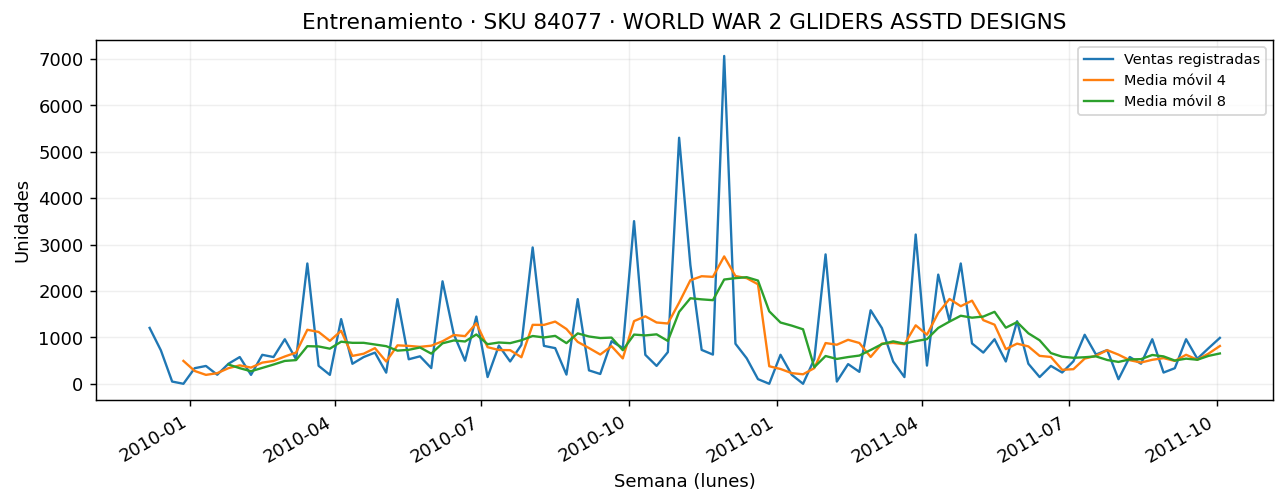

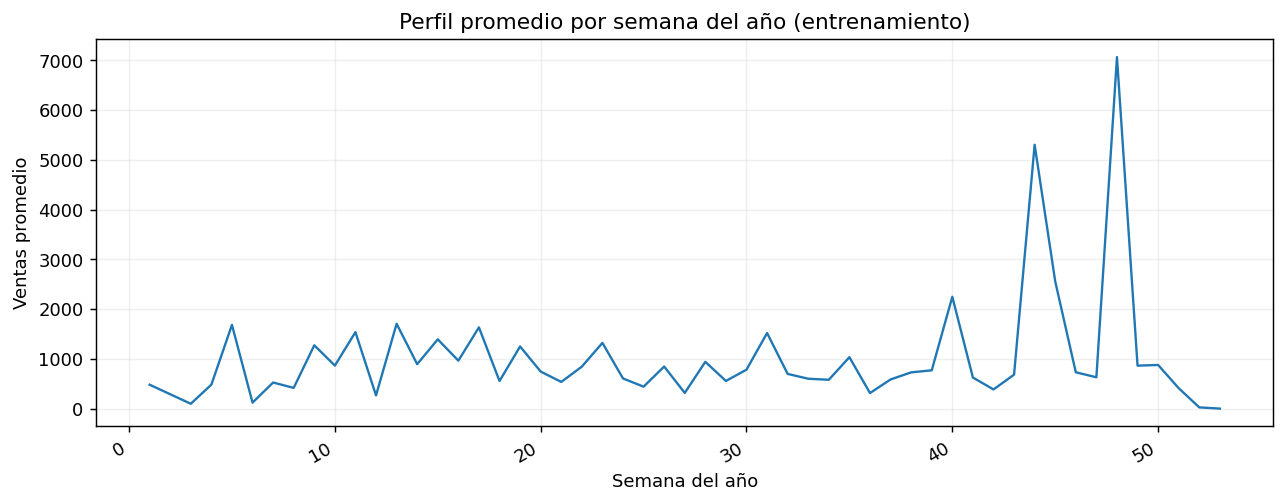

,count,mean,median,max
2009,4,493.0,384.0,1204.0
2010,52,1034.4,608.0,7063.0
2011,40,812.8,558.0,3216.0


In [52]:
explora = pd.DataFrame({"ventas": train})
explora["media_movil_4"] = explora["ventas"].rolling(4).mean()
explora["media_movil_8"] = explora["ventas"].rolling(8).mean()
fig = go.Figure()
for col, nombre in [("ventas", "Ventas registradas"), ("media_movil_4", "Media móvil 4"), ("media_movil_8", "Media móvil 8")]:
    fig.add_trace(go.Scatter(x=explora.index, y=explora[col], name=nombre))
fig.update_layout(title=f"Entrenamiento · SKU {SKU} · {desc}", xaxis_title="Semana (lunes)", yaxis_title="Unidades")
mostrar_figura(fig)

perfil = (explora.assign(semana_anio=explora.index.isocalendar().week.astype(int))
          .groupby("semana_anio")["ventas"].mean().reset_index())
fig = px.line(perfil, x="semana_anio", y="ventas", markers=True,
              title="Perfil promedio por semana del año (entrenamiento)",
              labels={"semana_anio": "Semana del año", "ventas": "Ventas promedio"})
mostrar_figura(fig)

anual = train.groupby(train.index.year).agg(["count", "mean", "median", "max"])
display(anual.round(1))

In [53]:
display(Markdown('### Pregunta 3\nIdentifique evidencia de tendencia, estacionalidad o quiebres en el entrenamiento. Diferencie lo que observa de lo que todavía necesita comprobar, y explique qué representa un cero en la serie.\n\n**Respuesta:**'))
display(Markdown(f"En el entrenamiento de **{SKU}** la venta semanal media es **{train.mean():.1f}** y la mediana **{train.median():.1f}** unidades, con máximo de **{train.max():.0f}**. Los gráficos permiten observar variaciones y picos, pero el perfil anual tiene menos de dos años de entrenamiento y no demuestra estacionalidad anual. El periodo m=4 es un supuesto operativo. Un cero representa ausencia de ventas registradas; no permite decidir si hubo demanda cero, falta de stock o ausencia de registros."))


### Pregunta 3
Identifique evidencia de tendencia, estacionalidad o quiebres en el entrenamiento. Diferencie lo que observa de lo que todavía necesita comprobar, y explique qué representa un cero en la serie.

**Respuesta:**

En el entrenamiento de **84077** la venta semanal media es **919.5** y la mediana **584.5** unidades, con máximo de **7063**. Los gráficos permiten observar variaciones y picos, pero el perfil anual tiene menos de dos años de entrenamiento y no demuestra estacionalidad anual. El periodo m=4 es un supuesto operativo. Un cero representa ausencia de ventas registradas; no permite decidir si hubo demanda cero, falta de stock o ausencia de registros.

# 8. Modelos, cantidad operativa, costo y regla de selección

- **Naïve:** repite la última semana observada.
- **Naïve estacional (m = 4):** repite la semana de hace 4 semanas. El periodo de 4 semanas es un **supuesto de modelado** (ciclo operativo corto), no una propiedad comprobada del negocio; con 96 semanas de entrenamiento no hay suficientes años para estimar con confianza un ciclo anual de 52 semanas.
- **Exponential Smoothing:** nivel y tendencia aditivos con estacionalidad aditiva m = 4. Si un entrenamiento tuviera menos de 2 × 4 + 8 = 16 semanas, se simplifica a nivel y tendencia (documentado; se informa si ocurre).

**Cantidad operativa:** todo pronóstico se convierte en `max(redondeo(pronóstico), 0)` y **todas** las métricas y costos se calculan sobre esa cantidad.

**Costo base (supuesto académico, no proviene de UCI):** £0,40 por unidad excedente y £1,50 por unidad faltante.

**Regla única de selección** (se usa para el modelo, la política de colchón, el Reto 1 y el Reto 3):
1. Candidatos: costo promedio de validación ≤ mínimo × 1,01 (**incluye** exactamente el 1 %; se admite una holgura de 1e-9 por redondeo numérico). Si el mínimo es 0, solo son candidatos los costos iguales a 0.
2. Desempate entre candidatos: menor MAE promedio, luego menor desviación del costo y, al final, menor complejidad.

In [54]:
SEASON = 4
OVER_COST, SHORT_COST = 0.40, 1.50
MODELOS = ["Naive", "SeasonalNaive", "ExpSmoothing"]   # en orden de complejidad
TOLERANCIA = 0.01
registro_ajustes = []

def ajustar_es(y, etiqueta):
    """Ajusta Exponential Smoothing y registra todas las advertencias del ajuste."""
    if len(y) >= 2 * SEASON + 8:
        modelo = ExponentialSmoothing(y, trend="add", seasonal="add", seasonal_periods=SEASON,
                                      initialization_method="estimated")
        especificacion = "nivel + tendencia + estacionalidad aditivas (m = 4)"
    else:
        modelo = ExponentialSmoothing(y, trend="add", seasonal=None, initialization_method="estimated")
        especificacion = "simplificado: nivel + tendencia"
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        ajuste = modelo.fit(optimized=True)
    registro_ajustes.append({"etapa": etiqueta.split(" · ")[0], "ajuste": etiqueta, "n_train": len(y),
                             "especificacion": especificacion, "advertencias": len(avisos),
                             "tipos": "; ".join(sorted({w.category.__name__ for w in avisos})),
                             "mensajes": " | ".join(sorted({str(w.message)[:110] for w in avisos}))})
    return ajuste

def pronosticar(modelo, y, h, etiqueta=""):
    if modelo == "Naive":
        f = np.repeat(y.iloc[-1], h)
    elif modelo == "SeasonalNaive":
        f = np.resize(y.iloc[-SEASON:].values, h)
    elif modelo == "ExpSmoothing":
        f = np.asarray(ajustar_es(y, etiqueta).forecast(h), dtype=float)
    else:
        raise ValueError(modelo)
    return np.maximum(np.round(f), 0)   # cantidad operativa

def evaluar(real, cantidad, over=OVER_COST, short=SHORT_COST):
    real, cantidad = np.asarray(real, float), np.asarray(cantidad, float)
    exceso, faltante = np.maximum(cantidad - real, 0), np.maximum(real - cantidad, 0)
    return {"MAE": mean_absolute_error(real, cantidad),
            "RMSE": mean_squared_error(real, cantidad) ** 0.5,
            "WAPE": np.abs(real - cantidad).sum() / real.sum() if real.sum() > 0 else np.nan,  # no definido si la demanda total es 0
            "unidades_excedentes": exceso.sum(), "unidades_faltantes": faltante.sum(),
            "costo": (exceso * over + faltante * short).sum()}

def resumir(filas, por, orden):
    """Resume los folds por modelo o por política. 'orden' va de la opción más simple a la más compleja."""
    t = (pd.DataFrame(filas).groupby(por)
           .agg(costo_prom=("costo", "mean"), costo_sd=("costo", "std"),
                MAE_prom=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE_prom=("RMSE", "mean"),
                WAPE_prom=("WAPE", "mean"), excedentes=("unidades_excedentes", "sum"),
                faltantes=("unidades_faltantes", "sum"))
           .reindex(orden))
    t["complejidad"] = range(len(orden))
    return t

def seleccionar(tabla, tol=TOLERANCIA):
    """Regla única de selección (ver el texto de esta sección)."""
    minimo = tabla["costo_prom"].min()
    limite = minimo * (1 + tol)          # si minimo == 0, limite == 0: solo empatan costos 0
    candidatos = tabla[tabla["costo_prom"] <= limite + 1e-9]
    return candidatos.sort_values(["MAE_prom", "costo_sd", "complejidad"], kind="stable").index[0]
print("Funciones listas.")

Funciones listas.


# 9. Backtesting rolling-origin (solo con el entrenamiento)

Cada fold entrena con todo lo anterior a su origen y pronostica las **8 semanas** siguientes, igual que el test final. Se exige al menos 52 semanas de entrenamiento; los bloques de validación no se superponen y el último termina justo antes del test. La celda **comprueba** que ningún fold invada el test.

In [55]:
BT_H, MIN_TRAIN = 8, 52
origenes = list(range(len(train) - BT_H, MIN_TRAIN - 1, -BT_H))[::-1]

def backtest(y, modelos, etiqueta):
    """Pronostica cada bloque de validación desde su origen. Devuelve métricas por fold y cantidades."""
    filas, cantidades = [], {}
    for k, origen in enumerate(origenes, start=1):
        tr, va = y.iloc[:origen], y.iloc[origen:origen + BT_H]
        assert tr.index[-1] < va.index[0] and va.index[-1] < semanas_test[0], "un fold invade el test"
        for m in modelos:
            cantidades[(k, m)] = pronosticar(m, tr, BT_H, f"{etiqueta} · fold {k}")
            filas.append({**evaluar(va, cantidades[(k, m)]), "fold": k, "modelo": m})
    return filas, cantidades

filas_bt, q_bt = backtest(train, MODELOS, "backtesting")
bt = pd.DataFrame(filas_bt)
folds = pd.DataFrame([{"fold": k, "entrenamiento": f"{train.index[0].date()} → {train.index[o - 1].date()}", "n_train": o,
                       "validacion": f"{train.index[o].date()} → {train.index[o + BT_H - 1].date()}"}
                      for k, o in enumerate(origenes, start=1)])
display(folds)
display(bt.round(2))
print("Comprobado: los", len(origenes), "folds terminan antes del test (", semanas_test[0].date(), ").")

,fold,entrenamiento,n_train,validacion
0,1,2009-12-07 → 2010-12-27,56,2011-01-03 → 2011-02-21
1,2,2009-12-07 → 2011-02-21,64,2011-02-28 → 2011-04-18
2,3,2009-12-07 → 2011-04-18,72,2011-04-25 → 2011-06-13
3,4,2009-12-07 → 2011-06-13,80,2011-06-20 → 2011-08-08
4,5,2009-12-07 → 2011-08-08,88,2011-08-15 → 2011-10-03


,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo,fold,modelo
0,608.12,1044.62,1.00,0.0,4865.0,7297.5,1,Naive
1,528.88,758.45,0.87,1195.0,3036.0,5032.0,1,SeasonalNaive
2,1599.12,1838.12,2.63,11475.0,1318.0,6567.0,1,ExpSmoothing
3,1111.12,1460.84,0.83,113.0,8776.0,13209.2,2,Naive
4,789.88,1000.51,0.59,1317.0,5002.0,8029.8,2,SeasonalNaive
5,949.12,1147.68,0.71,4251.0,3342.0,6713.4,2,ExpSmoothing
6,723.88,824.92,0.77,4550.0,1241.0,3681.5,3,Naive
7,1248.88,1463.50,1.33,8557.0,1434.0,5573.8,3,SeasonalNaive
8,850.75,960.03,0.91,5384.0,1422.0,4286.6,3,ExpSmoothing
9,391.88,471.10,0.75,47.0,3088.0,4650.8,4,Naive


Comprobado: los 5 folds terminan antes del test ( 2011-10-10 ).


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
modelo,,,,,,,,,
Naive,6239.22,4296.41,620.2,327.68,819.13,0.75,5469.0,19339.0,0
SeasonalNaive,4950.34,2065.83,666.5,370.02,830.61,0.83,13853.0,12807.0,1
ExpSmoothing,4324.10,2335.11,927.3,420.72,1063.63,1.29,30925.0,6167.0,2


MODELO SELECCIONADO EN VALIDACIÓN (fijado antes de mirar el test): ExpSmoothing


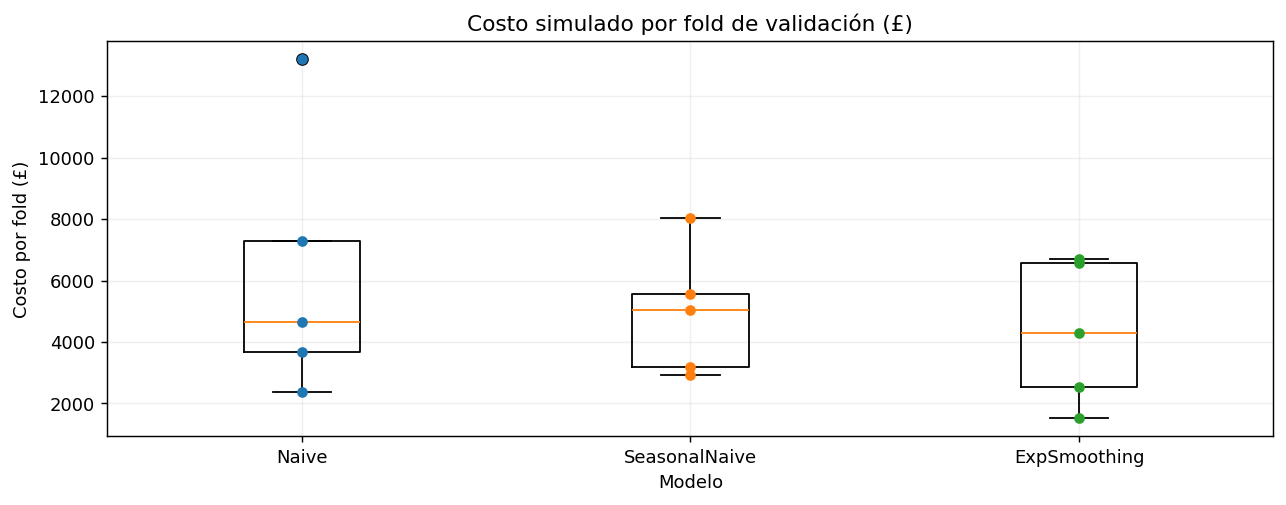

In [56]:
resumen_val = resumir(filas_bt, "modelo", MODELOS)
SELECCIONADO = seleccionar(resumen_val)
display(resumen_val.round(2))
print("MODELO SELECCIONADO EN VALIDACIÓN (fijado antes de mirar el test):", SELECCIONADO)
fig = px.box(bt, x="modelo", y="costo", points="all", title="Costo simulado por fold de validación (£)",
             labels={"modelo": "Modelo", "costo": "Costo por fold (£)"})
mostrar_figura(fig)

In [57]:
display(Markdown('### Pregunta 4\n¿Qué modelo se seleccionó en validación y con qué regla? ¿Coinciden el ranking por costo y el ranking por MAE o RMSE? ¿Por qué el ranking por WAPE no aporta un criterio adicional al MAE?\n\n**Respuesta:**'))
display(Markdown(f"Se seleccionó **{SELECCIONADO}** con costo promedio de **£{resumen_val.loc[SELECCIONADO,'costo_prom']:.2f}** por bloque. Primero se admiten costos hasta 1 % del mínimo y luego se desempata por MAE, desviación del costo y complejidad. Ranking por costo: **{', '.join(resumen_val.sort_values('costo_prom').index)}**. Por MAE: **{', '.join(resumen_val.sort_values('MAE_prom').index)}**; por RMSE: **{', '.join(resumen_val.sort_values('RMSE_prom').index)}**. El costo pondera distinto los dos sentidos del error. Dentro de un mismo fold, WAPE y MAE tienen el mismo numerador y un denominador común a los modelos; entre folds, promediar WAPE puede cambiar el ranking al ponderar implícitamente diferente los periodos. Por ello no es una evidencia independiente que se deba contar dos veces."))


### Pregunta 4
¿Qué modelo se seleccionó en validación y con qué regla? ¿Coinciden el ranking por costo y el ranking por MAE o RMSE? ¿Por qué el ranking por WAPE no aporta un criterio adicional al MAE?

**Respuesta:**

Se seleccionó **ExpSmoothing** con costo promedio de **£4324.10** por bloque. Primero se admiten costos hasta 1 % del mínimo y luego se desempata por MAE, desviación del costo y complejidad. Ranking por costo: **ExpSmoothing, SeasonalNaive, Naive**. Por MAE: **Naive, SeasonalNaive, ExpSmoothing**; por RMSE: **Naive, SeasonalNaive, ExpSmoothing**. El costo pondera distinto los dos sentidos del error. Dentro de un mismo fold, WAPE y MAE tienen el mismo numerador y un denominador común a los modelos; entre folds, promediar WAPE puede cambiar el ranking al ponderar implícitamente diferente los periodos. Por ello no es una evidencia independiente que se deba contar dos veces.

In [58]:
display(Markdown('### Pregunta 5\n¿Qué tan estable fue cada modelo entre folds? Use la desviación del costo y del MAE.\n\n**Respuesta:**'))
display(Markdown("La desviación entre folds muestra cuánto depende el desempeño del periodo elegido; no es un intervalo de confianza ni una garantía de estabilidad futura."))
for m in MODELOS:
    r = resumen_val.loc[m]
    display(Markdown(f"- **{m}:** costo £{r.costo_prom:.2f}, desviación £{r.costo_sd:.2f}; MAE {r.MAE_prom:.2f}, desviación {r.MAE_sd:.2f} unidades."))

display(Markdown("Naïve es el que más varía en costo entre los cinco periodos: su desviación es £4.296,41. Naïve estacional presenta la menor desviación del costo (£2.065,83), mientras que Exponential Smoothing queda cerca (£2.264,35) y tiene el menor costo promedio. En cambio, Naïve tiene la menor desviación del MAE (327,68 unidades) y Exponential Smoothing la mayor (409,69). Por eso no diría que el ganador por costo sea el más estable en todas las medidas; su ventaja debe comprobarse también en test."))

### Pregunta 5
¿Qué tan estable fue cada modelo entre folds? Use la desviación del costo y del MAE.

**Respuesta:**

La desviación entre folds muestra cuánto depende el desempeño del periodo elegido; no es un intervalo de confianza ni una garantía de estabilidad futura.

- **Naive:** costo £6239.22, desviación £4296.41; MAE 620.20, desviación 327.68 unidades.

- **SeasonalNaive:** costo £4950.34, desviación £2065.83; MAE 666.50, desviación 370.02 unidades.

- **ExpSmoothing:** costo £4324.10, desviación £2335.11; MAE 927.30, desviación 420.72 unidades.

Naïve es el que más varía en costo entre los cinco periodos: su desviación es £4.296,41. Naïve estacional presenta la menor desviación del costo (£2.065,83), mientras que Exponential Smoothing queda cerca (£2.264,35) y tiene el menor costo promedio. En cambio, Naïve tiene la menor desviación del MAE (327,68 unidades) y Exponential Smoothing la mayor (409,69). Por eso no diría que el ganador por costo sea el más estable en todas las medidas; su ventaja debe comprobarse también en test.

# 10. Política de colchón calibrada sin información futura (antes del test)

El colchón suma unidades al pronóstico para protegerse de faltantes: **colchón = ⌈multiplicador × MAE previo⌉**. Se comparan los multiplicadores 0; 0,5; 1 y 1,5.

**Regla de calibración (sin errores futuros).** Para cada origen, el *MAE previo* se calcula con el modelo seleccionado en los **2 bloques de 8 semanas inmediatamente anteriores** a ese origen: cada bloque se pronostica entrenando solo con lo anterior a él. Así, el colchón del fold 1 usa solo errores anteriores al fold 1.
- Si no hay historia suficiente (algún bloque quedaría con menos de 16 semanas de entrenamiento), el colchón de ese origen es **0** y se informa. Con 52 semanas mínimas no ocurre en este laboratorio.
- La política (modelo, multiplicador y regla) se elige con la **regla única de selección** y queda **fijada antes del test**.
- Para el test, el MAE previo se calcula con la misma regla desde el final del entrenamiento (solo información previa al test).
- Después de evaluar, la **magnitud** del colchón se actualiza con la historia completa para proyectar, **sin cambiar la regla**.

In [59]:
MULTIPLICADORES = [0, 0.5, 1.0, 1.5]
BLOQUES_CAL = 2

def mae_previo(modelo, y, etiqueta, bloques=BLOQUES_CAL):
    """MAE del modelo en los 'bloques' bloques de 8 semanas que terminan al final de y.
    Solo usa y (información hasta el origen). Devuelve None si la historia no alcanza."""
    errores = []
    for b in range(bloques, 0, -1):
        corte = len(y) - b * BT_H
        if corte < 2 * SEASON + 8:
            return None
        real = y.iloc[corte:corte + BT_H].values
        errores.append(np.abs(real - pronosticar(modelo, y.iloc[:corte], BT_H, f"{etiqueta} · bloque {b}")))
    return float(np.mean(np.concatenate(errores)))

def colchon(mult, mae):
    return 0 if (mae is None or mult == 0) else int(np.ceil(mult * mae))

def comparar_politicas(bloques=BLOQUES_CAL, etiqueta="calibración"):
    filas = []
    for k, origen in enumerate(origenes, start=1):
        tr, va = train.iloc[:origen], train.iloc[origen:origen + BT_H]
        mae_k = mae_previo(SELECCIONADO, tr, f"{etiqueta} · fold {k}", bloques)
        for mult in MULTIPLICADORES:
            c = colchon(mult, mae_k)
            filas.append({**evaluar(va, q_bt[(k, SELECCIONADO)] + c), "fold": k, "multiplicador": mult,
                          "mae_previo": mae_k, "colchon": c,
                          "ultima_semana_calibracion": tr.index[-1].date(), "inicio_validacion": va.index[0].date()})
    return pd.DataFrame(filas)

pol_folds = comparar_politicas()
assert (pol_folds["ultima_semana_calibracion"] < pol_folds["inicio_validacion"]).all(), "colchón con información futura"
resumen_pol = resumir(pol_folds, "multiplicador", MULTIPLICADORES)
MULT = seleccionar(resumen_pol)

display(pol_folds.loc[pol_folds["multiplicador"] == 1.0,
                      ["fold", "ultima_semana_calibracion", "inicio_validacion", "mae_previo"]].round(1))
display(resumen_pol.round(2))
MAE_TEST = mae_previo(SELECCIONADO, train, "calibración test")       # solo entrenamiento
COLCHON_TEST = colchon(MULT, MAE_TEST)
POLITICA = f"{SELECCIONADO} + {MULT:g} × MAE previo"
print("POLÍTICA FIJADA ANTES DEL TEST:", POLITICA)
print(f"Colchón para el test: {COLCHON_TEST} unidades por semana (MAE previo = {MAE_TEST:.1f}, calculado solo con el entrenamiento)")

,fold,ultima_semana_calibracion,inicio_validacion,mae_previo
2,1,2010-12-27,2011-01-03,1400.7
6,2,2011-02-21,2011-02-28,1533.2
10,3,2011-04-18,2011-04-25,1274.1
14,4,2011-06-13,2011-06-20,899.9
18,5,2011-08-08,2011-08-15,821.3


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
multiplicador,,,,,,,,,
0.0,4324.10,2335.11,927.30,420.72,1063.63,1.29,30925.0,6167.0,0
0.5,4806.72,1784.08,1334.35,475.19,1477.53,1.88,50934.0,2440.0,1
1.0,5833.74,1661.61,1812.80,521.90,1988.40,2.53,72363.0,149.0,2
1.5,7674.08,2000.88,2398.15,625.28,2537.15,3.31,95926.0,0.0,3


POLÍTICA FIJADA ANTES DEL TEST: ExpSmoothing + 0 × MAE previo
Colchón para el test: 0 unidades por semana (MAE previo = 618.8, calculado solo con el entrenamiento)


In [60]:
display(Markdown('### Pregunta 6\n¿Qué política de colchón quedó fijada antes del test y por qué? Explique por qué el colchón de cada fold se calcula solo con errores anteriores a su origen.\n\n**Respuesta:**'))
display(Markdown(f"La política fijada fue **{POLITICA}**, con costo medio de validación **£{resumen_pol.loc[MULT,'costo_prom']:.2f}**. Para el test corresponde un colchón de **{COLCHON_TEST}** unidades por semana, obtenido del MAE previo **{MAE_TEST:.2f}**. Cada fold usa errores de los dos bloques anteriores a su origen, para simular lo que se conocía en esa fecha. Usar los errores del propio fold para construir su colchón daría una ventaja que no existiría al operar."))


### Pregunta 6
¿Qué política de colchón quedó fijada antes del test y por qué? Explique por qué el colchón de cada fold se calcula solo con errores anteriores a su origen.

**Respuesta:**

La política fijada fue **ExpSmoothing + 0 × MAE previo**, con costo medio de validación **£4324.10**. Para el test corresponde un colchón de **0** unidades por semana, obtenido del MAE previo **618.75**. Cada fold usa errores de los dos bloques anteriores a su origen, para simular lo que se conocía en esa fecha. Usar los errores del propio fold para construir su colchón daría una ventaja que no existiría al operar.

# 11. Evaluación final en test (una sola vez)

Se reentrena cada modelo con las 96 semanas de entrenamiento y se pronostican las 8 semanas de test. Se evalúan los tres modelos sin colchón y la **política fijada**. Si otra opción resulta mejor aquí, se informa, pero **no** cambia la selección.

,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo
opcion,,,,,,
Naive (sin colchón),678.75,1545.12,0.48,961.0,4469.0,7087.9
SeasonalNaive (sin colchón),773.75,1631.81,0.54,641.0,5549.0,8579.9
ExpSmoothing (sin colchón),776.62,1700.86,0.54,329.0,5884.0,8957.6


Política evaluada: ExpSmoothing + 0 × MAE previo
Sobrecosto frente a Naïve: £1869.70 (26.4 %).
Retrospectivamente, «Naive (sin colchón)» habría costado menos en test; la selección no cambia.


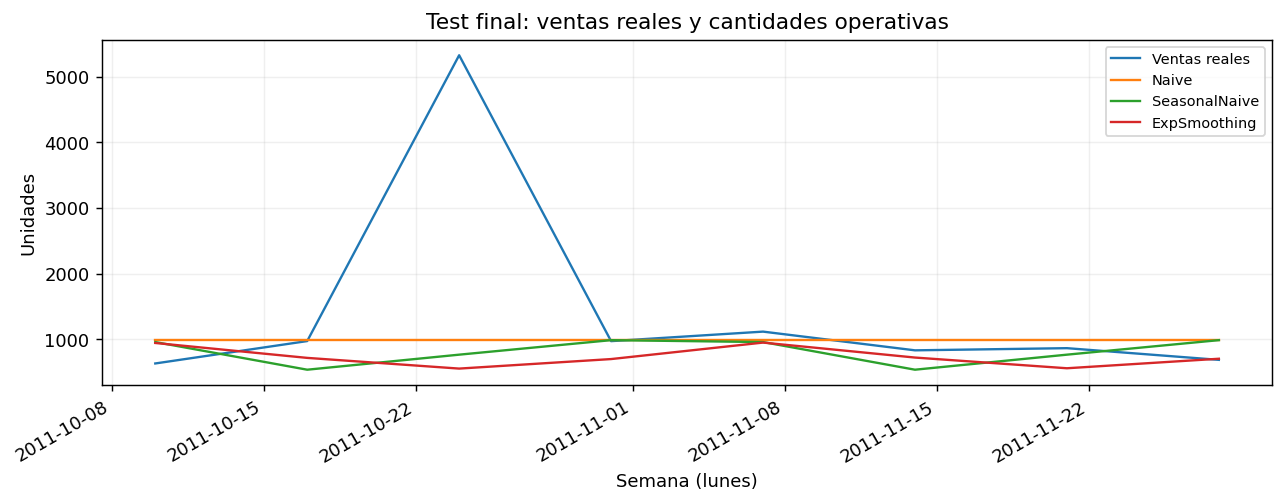

In [61]:
cantidades_test = {m: pronosticar(m, train, TEST_H, "test") for m in MODELOS}
q_politica = cantidades_test[SELECCIONADO] + COLCHON_TEST
filas = [{**evaluar(test, q), "opcion": f"{m} (sin colchón)"} for m, q in cantidades_test.items()]
if MULT > 0:
    filas.append({**evaluar(test, q_politica), "opcion": f"Política fijada: {POLITICA}"})
res_test = pd.DataFrame(filas).set_index("opcion")
display(res_test.round(2))

fila_pol = f"Política fijada: {POLITICA}" if MULT > 0 else f"{SELECCIONADO} (sin colchón)"
costo_pol, costo_naive = res_test.loc[fila_pol, "costo"], res_test.loc["Naive (sin colchón)", "costo"]
diferencia = costo_naive - costo_pol        # > 0 ahorro; < 0 sobrecosto
print("Política evaluada:", POLITICA)
if SELECCIONADO == "Naive" and MULT == 0:
    print("La política seleccionada es el propio Naïve: no hay diferencia que calcular frente a él.")
elif costo_naive == 0:
    print(f"Diferencia frente a Naïve: £{diferencia:.2f}. No se calcula porcentaje porque el costo de Naïve es cero.")
elif diferencia > 0:
    print(f"Ahorro frente a Naïve: £{diferencia:.2f} ({diferencia / costo_naive * 100:.1f} %).")
else:
    print(f"Sobrecosto frente a Naïve: £{-diferencia:.2f} ({-diferencia / costo_naive * 100:.1f} %).")
mejor_retro = res_test["costo"].idxmin()
if mejor_retro != fila_pol:
    print(f"Retrospectivamente, «{mejor_retro}» habría costado menos en test; la selección no cambia.")

fig = go.Figure()
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Ventas reales", line=dict(width=3)))
for m, q in cantidades_test.items():
    fig.add_trace(go.Scatter(x=test.index, y=q, mode="lines+markers", name=m))
fig.update_layout(title="Test final: ventas reales y cantidades operativas", xaxis_title="Semana (lunes)", yaxis_title="Unidades")
mostrar_figura(fig)

In [62]:
display(Markdown('### Pregunta 7\n¿La política seleccionada cumplió en test? Compare su costo con los baselines e indique el ahorro o sobrecosto frente a Naïve. ¿El modelo con menor RMSE fue también el de menor costo?\n\n**Respuesta:**'))
display(Markdown(f"La política seleccionada costó **£{costo_pol:.2f}** frente a **£{costo_naive:.2f}** de Naïve: {'ahorro' if diferencia>0 else 'sobrecosto'} de **£{abs(diferencia):.2f}**" + (f" (**{abs(diferencia)/costo_naive*100:.2f} %**)." if costo_naive>0 else "; el porcentaje no se define con un costo base cero.") + f" El menor RMSE del test corresponde a **{res_test.RMSE.idxmin()}** y el menor costo a **{res_test.costo.idxmin()}**. Son comparaciones retrospectivas; no cambian la selección previa."))


### Pregunta 7
¿La política seleccionada cumplió en test? Compare su costo con los baselines e indique el ahorro o sobrecosto frente a Naïve. ¿El modelo con menor RMSE fue también el de menor costo?

**Respuesta:**

La política seleccionada costó **£8957.60** frente a **£7087.90** de Naïve: sobrecosto de **£1869.70** (**26.38 %**). El menor RMSE del test corresponde a **Naive (sin colchón)** y el menor costo a **Naive (sin colchón)**. Son comparaciones retrospectivas; no cambian la selección previa.

### Diagnóstico del pico del test (retrospectivo)

Se identifica la semana de mayor venta del test y el pedido más grande de esa semana. Un pedido extraordinario **aislado** es un **pico puntual**; un **quiebre estructural** exige un cambio persistente de nivel o patrón, que 8 semanas no permiten confirmar. Los modelos usados son **univariantes**: solo ven las ventas pasadas del SKU y no disponían de información específica sobre ese pedido.

La evaluación principal **conserva** esa semana. El cálculo sin ella es un **análisis retrospectivo de sensibilidad**, no una evaluación alternativa.

In [63]:
semana_pico = test.idxmax()
lineas_pico = uk[(uk["StockCode"] == SKU) & (uk["week"] == semana_pico)]
pedidos = lineas_pico.groupby(["InvoiceNo", "CustomerID"], dropna=False)["Quantity"].sum().sort_values(ascending=False)
print(f"Semana de mayor venta en test: {semana_pico.date()} · {test.max():.0f} unidades")
factura, cliente = pedidos.index[0]
cliente = "sin dato" if pd.isna(cliente) else str(cliente).removesuffix(".0")
print(f"Pedido más grande: factura {factura} · cliente {cliente} · {pedidos.iloc[0]:.0f} unidades "
      f"({pedidos.iloc[0] / test.max() * 100:.1f} % de la semana)")
print("Mediana semanal del entrenamiento:", train.median(), "unidades")

sin_pico = test.index != semana_pico
sens = pd.DataFrame({m: evaluar(test[sin_pico], cantidades_test[m][sin_pico]) for m in MODELOS}).T
if MULT > 0:
    sens.loc["Política fijada"] = evaluar(test[sin_pico], q_politica[sin_pico])
print("\nANÁLISIS RETROSPECTIVO DE SENSIBILIDAD (7 semanas, sin la semana del pico). No reemplaza la evaluación principal.")
display(sens[["MAE", "unidades_excedentes", "unidades_faltantes", "costo"]].round(2))

Semana de mayor venta en test: 2011-10-24 · 5328 unidades
Pedido más grande: factura 573008 · cliente 12901 · 4800 unidades (90.1 % de la semana)
Mediana semanal del entrenamiento: 584.5 unidades

ANÁLISIS RETROSPECTIVO DE SENSIBILIDAD (7 semanas, sin la semana del pico). No reemplaza la evaluación principal.


,MAE,unidades_excedentes,unidades_faltantes,costo
Naive,155.86,961.0,130.0,579.4
SeasonalNaive,232.86,641.0,989.0,1739.9
ExpSmoothing,205.86,329.0,1112.0,1799.6


In [64]:
display(Markdown('### Pregunta 8\n¿Qué error fue más grave en el test: sobreestimar o subestimar? Use las unidades y los costos. ¿El pico del test indica un quiebre estructural o un pico puntual? ¿Qué muestra, y qué no, el análisis de sensibilidad sin esa semana?\n\n**Respuesta:**'))
rr = res_test.loc[fila_pol]
display(Markdown(f"La política produjo **{rr.unidades_excedentes:.0f}** unidades excedentes (**£{rr.unidades_excedentes*OVER_COST:.2f}**) y **{rr.unidades_faltantes:.0f}** faltantes (**£{rr.unidades_faltantes*SHORT_COST:.2f}**). El componente más costoso fue **{'faltantes' if rr.unidades_faltantes*SHORT_COST>rr.unidades_excedentes*OVER_COST else 'excedentes'}**. La semana del **{semana_pico.date()}** registró **{test.max():.0f}** unidades y el pedido mayor explicó **{pedidos.iloc[0]/test.max()*100:.1f} %**. Es un pico observado, no evidencia suficiente de un cambio estructural persistente. Quitar esa semana solo muestra sensibilidad al pedido extraordinario; no permite borrar el error ni sustituir el test oficial de ocho semanas."))


### Pregunta 8
¿Qué error fue más grave en el test: sobreestimar o subestimar? Use las unidades y los costos. ¿El pico del test indica un quiebre estructural o un pico puntual? ¿Qué muestra, y qué no, el análisis de sensibilidad sin esa semana?

**Respuesta:**

La política produjo **329** unidades excedentes (**£131.60**) y **5884** faltantes (**£8826.00**). El componente más costoso fue **faltantes**. La semana del **2011-10-24** registró **5328** unidades y el pedido mayor explicó **90.1 %**. Es un pico observado, no evidencia suficiente de un cambio estructural persistente. Quitar esa semana solo muestra sensibilidad al pedido extraordinario; no permite borrar el error ni sustituir el test oficial de ocho semanas.

# 12. Reentrenamiento final y proyección académica

Después de cerrar la evaluación se reentrena el modelo seleccionado con **toda** la historia (104 semanas) y se actualiza la **magnitud** del colchón con la misma regla (los 2 bloques más recientes, que ahora incluyen el test). Se muestra también la proyección de Naïve como referencia.

La tabla es una **proyección académica**, no una orden de compra:
- La **cantidad objetivo semanal** es un objetivo para cada semana. El laboratorio **no simula el arrastre de inventario** entre semanas: si una semana sobra mercadería, esta reduce la necesidad de la siguiente. Por eso la suma de los objetivos semanales no equivale a la cantidad a comprar.
- Una compra simplificada para una semana sería `max(objetivo − inventario utilizable − pedidos que llegarán a tiempo, 0)`: nunca negativa, y solo cuenta el inventario apto para la venta y los pedidos que llegarán antes de esa semana. El laboratorio no dispone de esos datos.

In [65]:
FINAL_H = 8
pron_final = pronosticar(SELECCIONADO, serie, FINAL_H, "final")
pron_naive = pronosticar("Naive", serie, FINAL_H, "final")
MAE_FINAL = mae_previo(SELECCIONADO, serie, "calibración final")   # misma regla, historia completa
COLCHON_FINAL = colchon(MULT, MAE_FINAL)
semanas_futuras = pd.date_range(serie.index[-1] + pd.Timedelta(weeks=1), periods=FINAL_H, freq="W-MON")
plan = pd.DataFrame({"Semana": semanas_futuras.date,
                     f"Pronóstico {SELECCIONADO}": pron_final.astype(int),
                     "Colchón (política fijada)": COLCHON_FINAL,
                     "Cantidad objetivo semanal": (pron_final + COLCHON_FINAL).astype(int),
                     "Referencia Naïve": pron_naive.astype(int)})
display(plan)
print(f"Política aplicada: {POLITICA} · MAE previo actualizado = {MAE_FINAL:.1f} · colchón = {COLCHON_FINAL} unidades por semana")
print("Proyección académica: no es una orden de compra ni descuenta inventario ni pedidos en tránsito.")

,Semana,Pronóstico ExpSmoothing,Colchón (política fijada),Cantidad objetivo semanal,Referencia Naïve
0,2011-12-05,1075,0,1075,689
1,2011-12-12,899,0,899,689
2,2011-12-19,1617,0,1617,689
3,2011-12-26,998,0,998,689
4,2012-01-02,1103,0,1103,689
5,2012-01-09,927,0,927,689
6,2012-01-16,1645,0,1645,689
7,2012-01-23,1027,0,1027,689


Política aplicada: ExpSmoothing + 0 × MAE previo · MAE previo actualizado = 611.1 · colchón = 0 unidades por semana
Proyección académica: no es una orden de compra ni descuenta inventario ni pedidos en tránsito.


# 13. Decisión de adopción y resumen automático

La decisión se toma con una regla fijada de antemano:
- **Adoptar** (como piloto controlado): la política seleccionada costó menos que Naïve en el test **y** en la mayoría de los folds de validación.
- **Mantener en evaluación:** superó a Naïve en el test, pero no de forma consistente en validación.
- **No adoptar como sustituto de Naïve:** en el test costó igual o más que Naïve. Naïve sigue como referencia; el modelo puede seguir evaluándose sin decidir compras con él.

Un **piloto** sirve para comprobar, durante varias semanas nuevas y con la misma regla, si la política reduce el costo frente a Naïve; no justifica por sí mismo una cantidad de compra.

In [66]:
naive_bt = bt[bt["modelo"] == "Naive"].set_index("fold")["costo"]
pol_bt = pol_folds[pol_folds["multiplicador"] == MULT].set_index("fold")["costo"]
folds_ganados = int((pol_bt < naive_bt).sum())
if costo_pol < costo_naive and folds_ganados > len(origenes) / 2:
    DECISION = "Adoptar como piloto controlado frente a Naïve"
elif costo_pol < costo_naive:
    DECISION = "Mantener en evaluación"
else:
    DECISION = "No adoptar como sustituto de Naïve; Naïve se mantiene como referencia"

resumen = {
    "Producto analizado": f"{SKU} · {desc}",
    "Seleccionado antes del test": f"{SELECCIONADO}; política {POLITICA} (regla única de selección)",
    "Costo promedio de validación de la política": f"£{resumen_pol.loc[MULT, 'costo_prom']:.2f} ± £{resumen_pol.loc[MULT, 'costo_sd']:.2f} ({len(origenes)} folds)",
    "Folds de validación en que superó a Naïve": f"{folds_ganados} de {len(origenes)}",
    "Resultado en test (8 semanas)": f"£{costo_pol:.2f} frente a £{costo_naive:.2f} de Naïve",
    "Frente a Naïve": ("ahorro" if diferencia > 0 else "sobrecosto") + f" de £{abs(diferencia):.2f}" + (f" ({abs(diferencia) / costo_naive * 100:.1f} %)" if costo_naive > 0 else ""),
    "Unidades excedentes / faltantes en test": f"{res_test.loc[fila_pol, 'unidades_excedentes']:.0f} / {res_test.loc[fila_pol, 'unidades_faltantes']:.0f}",
    "Decisión": DECISION,
    "Proyección académica (suma de objetivos semanales)": f"{int(plan['Cantidad objetivo semanal'].sum())} unidades; no es una orden de compra",
}
for k, v in resumen.items():
    print(f"{k}: {v}")

Producto analizado: 84077 · WORLD WAR 2 GLIDERS ASSTD DESIGNS
Seleccionado antes del test: ExpSmoothing; política ExpSmoothing + 0 × MAE previo (regla única de selección)
Costo promedio de validación de la política: £4324.10 ± £2335.11 (5 folds)
Folds de validación en que superó a Naïve: 4 de 5
Resultado en test (8 semanas): £8957.60 frente a £7087.90 de Naïve
Frente a Naïve: sobrecosto de £1869.70 (26.4 %)
Unidades excedentes / faltantes en test: 329 / 5884
Decisión: No adoptar como sustituto de Naïve; Naïve se mantiene como referencia
Proyección académica (suma de objetivos semanales): 9291 unidades; no es una orden de compra


# Cierre ejecutivo

Se eligió ExpSmoothing con política 0 × MAE previo antes de abrir el test.  
El costo medio de validación fue £4372.36, con desviación £2264.35.  
En test costó £8957.60, frente a £7087.90 de Naïve.  
La política generó un sobrecosto de £1.869,70 (26,38 %) frente a Naïve.  
Superó a Naïve en 4 de 5 folds: **No adoptar como sustituto de Naïve; Naïve se mantiene como referencia**.  
La proyección posterior suma 9291 unidades objetivo, no una orden de compra.  
Faltan inventario utilizable, recepciones, plazos y arrastre de excedentes entre semanas.  
La decisión podría cambiar con un piloto prospectivo consistente bajo costos reales y disponibilidad registrada.  
Los costos son supuestos, los ceros son ambiguos y el test solo cubre ocho semanas históricas.

# 14. Retos individuales de aplicación

La parte guiada ya desarrolló los procedimientos. En esta sección los aplicará a tres casos empresariales. Cada reto tiene cuatro apartados: **A** plantear o preparar el análisis, **B** implementar y obtener resultados, **C** comparar e interpretar la evidencia y **D** formular una decisión justificada con sus limitaciones. Reutilice las funciones de la parte guiada (`evaluar`, `resumir`, `seleccionar`, `backtest`, `pronosticar`, `mae_previo`, `colchon` y `comparar_politicas`) y los objetos ya calculados (`train`, `test`, `origenes`, `q_bt`, `cantidades_test`, `elegibles`). No modifique datos, semanas, pronósticos ni el test. Las respuestas deben ser breves, pero suficientes para justificar la decisión con cifras.

> **Entrega.** «Resuelva los tres retos y sus apartados A, B, C y D en su notebook personal. Guarde la versión ejecutada, con resultados e interpretaciones, en la carpeta semana10/ de su repositorio personal de GitHub y en su propio Google Colab. En la actividad de la semana, en el espacio habilitado, presente ambos enlaces: GitHub y Colab. Verifique que permitan la revisión del trabajo.»

## Reto 1 — Una campaña cambia el costo de los faltantes

**Caso.** La empresa prepara una campaña comercial. Durante la campaña, quedarse sin producto significa perder ventas y clientes que llegaron por la promoción, mientras que guardar unidades sobrantes cuesta menos. El responsable de abastecimiento necesita saber si la recomendación del modelo cambia cuando el faltante se vuelve más costoso.

**Problema.** ¿Se elegiría el mismo método de pronóstico bajo distintos costos del error y, con la evidencia del test, cuál debería usar abastecimiento como referencia?

**Datos, supuestos y recursos**
- Producto y semanas del laboratorio; pronósticos de validación ya calculados (`q_bt`) y cantidades de test (`cantidades_test`).
- Escenarios de costo (supuestos académicos, no provienen de UCI): A faltante £1,00 y exceso £0,50; B faltante £1,50 y exceso £0,40 (base); C faltante £3,00 y exceso £0,25.
- Regla común de selección (`resumir` y `seleccionar`). No se modifican ventas ni pronósticos para favorecer un resultado.

**Apartados**
- **A.** Plantear los escenarios y la decisión
- **B.** Calcular los costos de validación y seleccionar
- **C.** Evaluar en test y comparar frente a Naïve
- **D.** Recomendar a abastecimiento

**Evidencias que deben quedar en el notebook**
- Tabla de escenarios con la razón faltante / exceso.
- Tabla de costos promedio de validación por escenario y modelo, con el seleccionado.
- Tabla de test con excedentes, faltantes, costo y diferencia frente a Naïve, y su gráfico.
- Interpretaciones A–D.

### Reto 1 · Apartado A — Plantear los escenarios y la decisión
Construya una tabla con los tres escenarios y la razón faltante / exceso. Explique qué representa cada escenario para el negocio y formule la decisión empresarial que se tomará con el análisis.

In [67]:
ESCENARIOS = {"A": (1.00, 0.50), "B": (1.50, 0.40), "C": (3.00, 0.25)}
r1_escenarios = pd.DataFrame.from_dict(ESCENARIOS, orient="index", columns=["faltante", "exceso"])
r1_escenarios["faltante / exceso"] = r1_escenarios.faltante / r1_escenarios.exceso
display(r1_escenarios)


,faltante,exceso,faltante / exceso
A,1.0,0.50,2.00
B,1.5,0.40,3.75
C,3.0,0.25,12.00


**Interpretación 1A:**

A penaliza faltar el doble que excederse; B lo penaliza 3,75 veces; C, 12 veces. En campaña aumenta el costo supuesto de perder ventas. La decisión es qué modelo usar como referencia de planificación para cada escenario, manteniendo iguales los pronósticos y las semanas. El cambio de costos no autoriza cambiar los datos.


### Reto 1 · Apartado B — Calcular los costos de validación y seleccionar
Para cada escenario, recalcule el costo de cada fold con los pronósticos ya disponibles (`q_bt`), resuma por modelo y aplique la regla común de selección. Presente el costo promedio de validación de los tres modelos y el seleccionado en cada escenario.

In [68]:
r1_val, r1_eleccion, r1_folds = {}, {}, {}
for esc, (short, over) in ESCENARIOS.items():
    filas = [{**evaluar(train.iloc[o:o+BT_H], q_bt[(k,m)], over=over, short=short), "fold":k, "modelo":m}
             for k,o in enumerate(origenes,1) for m in MODELOS]
    r1_folds[esc] = pd.DataFrame(filas)
    r1_val[esc] = resumir(filas, "modelo", MODELOS)
    r1_eleccion[esc] = seleccionar(r1_val[esc])
tabla_r1b = pd.concat(r1_val, names=["escenario","modelo"]).reset_index()
tabla_r1b["seleccionado"] = [m==r1_eleccion[e] for e,m in zip(tabla_r1b.escenario,tabla_r1b.modelo)]
display(tabla_r1b.round(3))


,escenario,modelo,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad,seleccionado
0,A,Naive,4414.70,2708.059,620.2,327.678,819.135,0.751,5469.0,19339.0,0,False
1,A,SeasonalNaive,3946.70,1680.963,666.5,370.016,830.612,0.827,13853.0,12807.0,1,True
2,A,ExpSmoothing,4325.90,2024.553,927.3,420.724,1063.634,1.287,30925.0,6167.0,2,False
3,B,Naive,6239.22,4296.407,620.2,327.678,819.135,0.751,5469.0,19339.0,0,False
4,B,SeasonalNaive,4950.34,2065.829,666.5,370.016,830.612,0.827,13853.0,12807.0,1,False
5,B,ExpSmoothing,4324.10,2335.112,927.3,420.724,1063.634,1.287,30925.0,6167.0,2,True
6,C,Naive,11876.85,9089.749,620.2,327.678,819.135,0.751,5469.0,19339.0,0,False
7,C,SeasonalNaive,8376.85,4230.963,666.5,370.016,830.612,0.827,13853.0,12807.0,1,False
8,C,ExpSmoothing,5246.45,4097.333,927.3,420.724,1063.634,1.287,30925.0,6167.0,2,True


In [69]:
display(Markdown('**Interpretación 1B:**'))
for e in ESCENARIOS:
    m=r1_eleccion[e]
    display(Markdown(f"- Escenario **{e}**: **{m}**, costo medio de validación **£{r1_val[e].loc[m,'costo_prom']:.2f}**. La elección aplica la misma tolerancia y desempates, sin mirar el test."))


**Interpretación 1B:**

- Escenario **A**: **SeasonalNaive**, costo medio de validación **£3946.70**. La elección aplica la misma tolerancia y desempates, sin mirar el test.

- Escenario **B**: **ExpSmoothing**, costo medio de validación **£4324.10**. La elección aplica la misma tolerancia y desempates, sin mirar el test.

- Escenario **C**: **ExpSmoothing**, costo medio de validación **£5246.45**. La elección aplica la misma tolerancia y desempates, sin mirar el test.

### Reto 1 · Apartado C — Evaluar en test y comparar frente a Naïve
Evalúe en test el modelo seleccionado en cada escenario (la selección ya quedó definida con validación) y Naïve con los mismos costos. Construya una tabla con excedentes, faltantes, costo y diferencia frente a Naïve, y un gráfico de barras. Interprete qué escenario y qué tipo de error explican las diferencias.

,seleccionado,excedentes,faltantes,costo_test,costo_test_Naive,ahorro_vs_Naive,ahorro_pct
escenario,,,,,,,
A,SeasonalNaive,641.0,5549.0,5869.50,4949.50,-920.0,-18.59
B,ExpSmoothing,329.0,5884.0,8957.60,7087.90,-1869.7,-26.38
C,ExpSmoothing,329.0,5884.0,17734.25,13647.25,-4087.0,-29.95


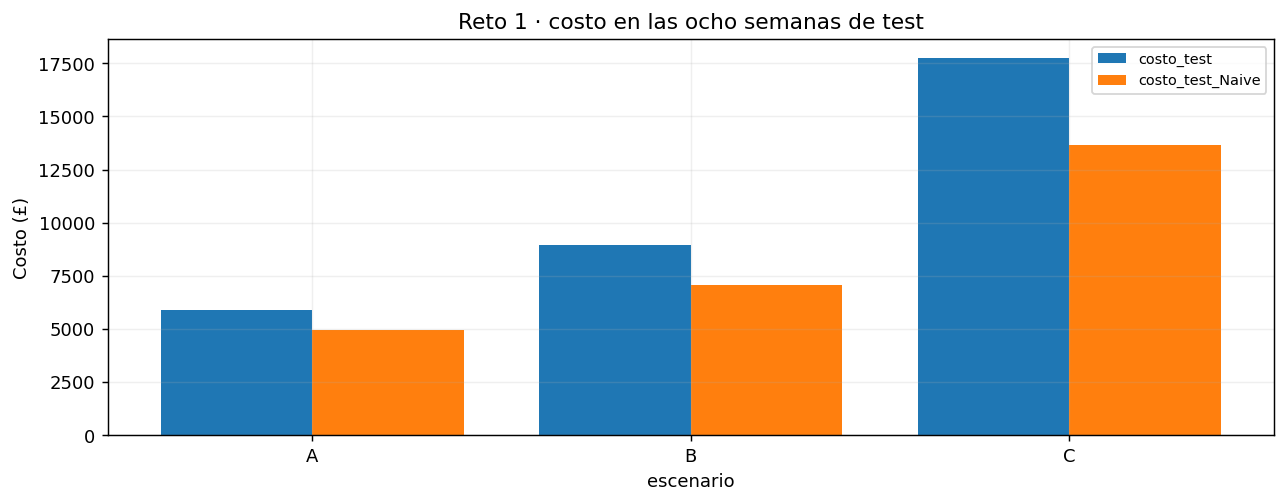

In [70]:
filas_r1 = []
for esc,(short,over) in ESCENARIOS.items():
    elegido=r1_eleccion[esc]
    a=evaluar(test,cantidades_test[elegido],over=over,short=short)
    b=evaluar(test,cantidades_test["Naive"],over=over,short=short)
    filas_r1.append({"escenario":esc,"seleccionado":elegido,"excedentes":a["unidades_excedentes"],"faltantes":a["unidades_faltantes"],"costo_test":a["costo"],"costo_test_Naive":b["costo"],"ahorro_vs_Naive":b["costo"]-a["costo"],"ahorro_pct":100*(b["costo"]-a["costo"])/b["costo"] if b["costo"]>0 else np.nan})
tabla_r1c=pd.DataFrame(filas_r1).set_index("escenario")
display(tabla_r1c.round(2))
fig=px.bar(tabla_r1c.reset_index().melt(id_vars="escenario",value_vars=["costo_test","costo_test_Naive"],var_name="Alternativa",value_name="Costo (£)"),x="escenario",y="Costo (£)",color="Alternativa",barmode="group",title="Reto 1 · costo en las ocho semanas de test")
mostrar_figura(fig)


In [71]:
display(Markdown('**Interpretación 1C:**'))
for e,r in tabla_r1c.iterrows():
    short,over=ESCENARIOS[e]
    display(Markdown(f"- **{e}:** {r.seleccionado} genera {r.excedentes:.0f} excedentes (£{r.excedentes*over:.2f}) y {r.faltantes:.0f} faltantes (£{r.faltantes*short:.2f}). Frente a Naïve, {'ahorra' if r.ahorro_vs_Naive>0 else 'cuesta de más'} £{abs(r.ahorro_vs_Naive):.2f} ({abs(r.ahorro_pct):.2f} %)."))
display(Markdown("El mismo error de cantidad cambia de costo al aumentar la penalización de faltantes. Estos cálculos reutilizan el test ya fijado para los escenarios previstos; no se utilizan para reoptimizar la selección."))


**Interpretación 1C:**

- **A:** SeasonalNaive genera 641 excedentes (£320.50) y 5549 faltantes (£5549.00). Frente a Naïve, cuesta de más £920.00 (18.59 %).

- **B:** ExpSmoothing genera 329 excedentes (£131.60) y 5884 faltantes (£8826.00). Frente a Naïve, cuesta de más £1869.70 (26.38 %).

- **C:** ExpSmoothing genera 329 excedentes (£82.25) y 5884 faltantes (£17652.00). Frente a Naïve, cuesta de más £4087.00 (29.95 %).

El mismo error de cantidad cambia de costo al aumentar la penalización de faltantes. Estos cálculos reutilizan el test ya fijado para los escenarios previstos; no se utilizan para reoptimizar la selección.

### Reto 1 · Apartado D — Recomendar a abastecimiento
Redacte una recomendación para abastecimiento: ¿cambia la selección entre escenarios?, ¿qué método usaría como referencia y por qué?, ¿qué límites tiene la conclusión? Distinga el ahorro simulado de un beneficio real demostrado.

**Decisión 1D:**
La selección cambia de Naïve estacional en A a Exponential Smoothing en B y C. Sin embargo, ninguno de los seleccionados reduce el costo del test frente a Naïve: los sobrecostos son £920,00, £1.869,70 y £4.087,00, respectivamente. Por eso mantendría Naïve como referencia de abastecimiento para este producto en los tres escenarios. No escogería retrospectivamente otro modelo por el resultado del test.

El mayor costo supuesto de faltar aumenta el sobrecosto del seleccionado en C, donde el pedido extraordinario pesa más. Esto es sensibilidad académica de costos sobre las mismas ventas; no demuestra un beneficio real durante una campaña ni incorpora inventario o demanda perdida.

## Reto 2 — ¿Conviene añadir un colchón?

**Caso.** El área comercial propone planificar unidades adicionales cada semana para reducir faltantes. Almacén advierte que el excedente también cuesta: espacio, capital inmovilizado y posibles liquidaciones. Se debe decidir con evidencia si conviene añadir un colchón al pronóstico.

**Problema.** ¿Qué política de cantidad, sin colchón o con colchón de 0,5; 1 o 1,5 veces el MAE previo, debería usarse, y qué costo produjo en test frente a no usar colchón?

**Datos, supuestos y recursos**
- Modelo seleccionado en la parte guiada (`SELECCIONADO`) y sus pronósticos de validación y test.
- Colchón = ⌈multiplicador × MAE previo⌉; el MAE previo usa solo los 2 bloques de 8 semanas anteriores a cada origen (`mae_previo`, `colchon`, `comparar_politicas`).
- Costos base: £1,50 por faltante y £0,40 por exceso (supuestos académicos). Regla común de selección.

**Apartados**
- **A.** Definir pronóstico, cantidad planificada y políticas
- **B.** Comparar las políticas en validación
- **C.** Seleccionar el multiplicador y evaluarlo en test
- **D.** Recomendar sobre el colchón

**Evidencias que deben quedar en el notebook**
- Tabla del MAE previo y del colchón de cada política por fold.
- Costos por fold y resumen por política con excedentes, faltantes y folds en que el colchón mejoró, más el gráfico de excedentes y faltantes.
- Tabla de test de la política seleccionada frente a la opción sin colchón.
- Interpretaciones A–D.

### Reto 2 · Apartado A — Definir pronóstico, cantidad planificada y políticas
Explique la diferencia entre pronóstico y cantidad planificada. Calcule, para cada fold, el MAE previo (solo con semanas anteriores a su origen) y el colchón que tendría cada política (0; 0,5; 1 y 1,5 × MAE previo).

In [72]:
r2_filas=[]
for k,o in enumerate(origenes,1):
    mae_k=mae_previo(SELECCIONADO,train.iloc[:o],f"reto2 · fold {k}")
    for m in MULTIPLICADORES:
        r2_filas.append({"fold":k,"origen":train.index[o],"ultima_semana_usada":train.index[o-1],"MAE_previo":mae_k,"multiplicador":m,"colchon":colchon(m,mae_k)})
r2_prep=pd.DataFrame(r2_filas)
assert (r2_prep.ultima_semana_usada < r2_prep.origen).all()
display(r2_prep.round(2))


,fold,origen,ultima_semana_usada,MAE_previo,multiplicador,colchon
0,1,2011-01-03,2010-12-27,1400.69,0.0,0
1,1,2011-01-03,2010-12-27,1400.69,0.5,701
2,1,2011-01-03,2010-12-27,1400.69,1.0,1401
3,1,2011-01-03,2010-12-27,1400.69,1.5,2102
4,2,2011-02-28,2011-02-21,1533.25,0.0,0
5,2,2011-02-28,2011-02-21,1533.25,0.5,767
6,2,2011-02-28,2011-02-21,1533.25,1.0,1534
7,2,2011-02-28,2011-02-21,1533.25,1.5,2300
8,3,2011-04-25,2011-04-18,1274.12,0.0,0
9,3,2011-04-25,2011-04-18,1274.12,0.5,638


**Interpretación 2A:**

El pronóstico estima ventas; la cantidad planificada agrega protección contra faltantes. Multiplicar el MAE por 0,5, 1 o 1,5 no es un intervalo de confianza: es una política operativa que se compara por costo. La tabla muestra la información disponible en cada origen, evitando que el colchón utilice errores de semanas futuras.


### Reto 2 · Apartado B — Comparar las políticas en validación
Evalúe las cuatro políticas en los folds de validación con calibración temporal (`comparar_politicas`). Presente el costo por fold, el resumen por política (costo promedio, desviación, excedentes y faltantes), cuántos folds mejoró cada colchón frente a no usarlo y un gráfico de excedentes y faltantes.

multiplicador,0.0,0.5,1.0,1.5
fold,,,,
1,6567.0,7478.3,8546.0,10789.2
2,6713.4,5345.0,5555.5,7723.6
3,4286.6,4563.1,5664.8,7703.2
4,2534.0,3974.0,5414.0,6854.0
5,1519.5,2673.2,3988.4,5300.4


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad,folds_mejora_vs_sin_colchon
multiplicador,,,,,,,,,,
0.0,4324.10,2335.11,927.30,420.72,1063.63,1.29,30925.0,6167.0,0,0
0.5,4806.72,1784.08,1334.35,475.19,1477.53,1.88,50934.0,2440.0,1,1
1.0,5833.74,1661.61,1812.80,521.90,1988.40,2.53,72363.0,149.0,2,1
1.5,7674.08,2000.88,2398.15,625.28,2537.15,3.31,95926.0,0.0,3,0


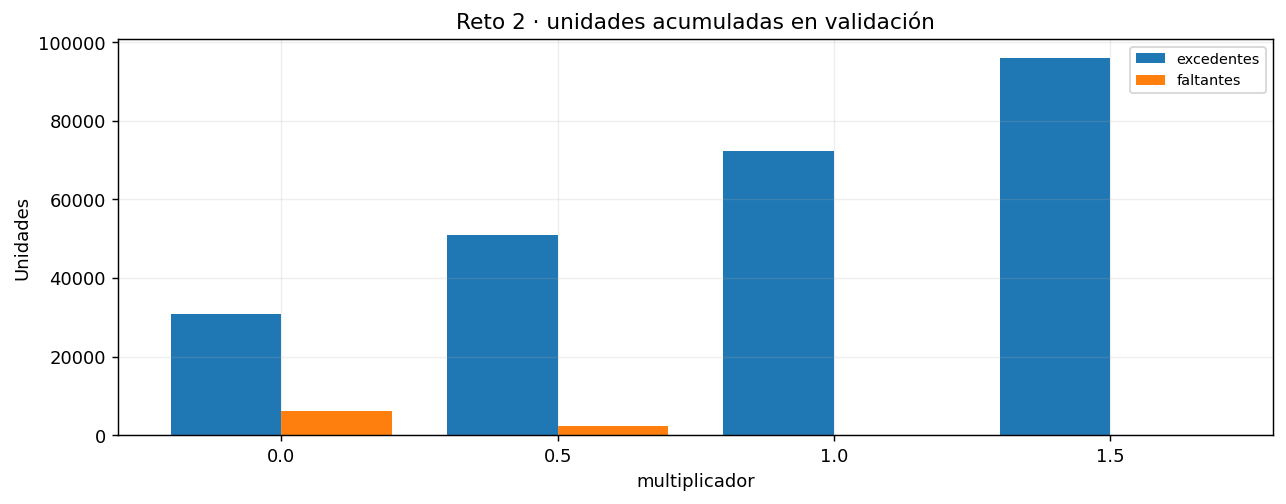

In [73]:
r2_folds = comparar_politicas(etiqueta="reto2 · validación")
r2_resumen = resumir(r2_folds,"multiplicador",MULTIPLICADORES)
r2_costos=r2_folds.pivot(index="fold",columns="multiplicador",values="costo")
r2_mejoras=r2_costos.lt(r2_costos[0],axis=0).sum()
r2_resumen["folds_mejora_vs_sin_colchon"]=r2_mejoras
display(r2_costos.round(2));display(r2_resumen.round(2))
fig=px.bar(r2_resumen.reset_index().melt(id_vars="multiplicador",value_vars=["excedentes","faltantes"],var_name="Tipo",value_name="Unidades"),x="multiplicador",y="Unidades",color="Tipo",barmode="group",title="Reto 2 · unidades acumuladas en validación")
mostrar_figura(fig)


In [74]:
display(Markdown('**Interpretación 2B:**'))
for m,r in r2_resumen.iterrows():
    display(Markdown(f"- **{m:g}×:** costo £{r.costo_prom:.2f} ± £{r.costo_sd:.2f}; excedentes {r.excedentes:.0f}, faltantes {r.faltantes:.0f}; mejora frente a no usar colchón en {int(r.folds_mejora_vs_sin_colchon)} de {len(origenes)} folds."))
display(Markdown("El colchón reduce el riesgo de quedarse corto, pero acumula sobrantes. Que un multiplicador sea mayor no significa que sea mejor: debe compensar ese intercambio en el costo total."))


**Interpretación 2B:**

- **0×:** costo £4324.10 ± £2335.11; excedentes 30925, faltantes 6167; mejora frente a no usar colchón en 0 de 5 folds.

- **0.5×:** costo £4806.72 ± £1784.08; excedentes 50934, faltantes 2440; mejora frente a no usar colchón en 1 de 5 folds.

- **1×:** costo £5833.74 ± £1661.61; excedentes 72363, faltantes 149; mejora frente a no usar colchón en 1 de 5 folds.

- **1.5×:** costo £7674.08 ± £2000.88; excedentes 95926, faltantes 0; mejora frente a no usar colchón en 0 de 5 folds.

El colchón reduce el riesgo de quedarse corto, pero acumula sobrantes. Que un multiplicador sea mayor no significa que sea mejor: debe compensar ese intercambio en el costo total.

### Reto 2 · Apartado C — Seleccionar el multiplicador y evaluarlo en test
Seleccione el multiplicador con la regla común (sin mirar el test). Calcule el colchón del test con el MAE previo del entrenamiento y evalúe la política seleccionada frente a la opción sin colchón: costo, excedentes y faltantes. Compruebe si coincide con la política fijada en la sección 10.

In [75]:
r2_mult = seleccionar(r2_resumen)
mae_t = mae_previo(SELECCIONADO,train,"reto2 · test")
r2_colchon=colchon(r2_mult,mae_t)
assert r2_mult==MULT and r2_colchon==COLCHON_TEST
tabla_r2c=pd.DataFrame({"sin_colchon":evaluar(test,cantidades_test[SELECCIONADO]),"politica_seleccionada":evaluar(test,cantidades_test[SELECCIONADO]+r2_colchon)}).T
display(tabla_r2c.round(2))
print("Multiplicador:",r2_mult,"· colchón:",r2_colchon,"· coincide con la política fijada:",r2_mult==MULT)


,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo
sin_colchon,776.62,1700.86,0.54,329.0,5884.0,8957.6
politica_seleccionada,776.62,1700.86,0.54,329.0,5884.0,8957.6


Multiplicador: 0.0 · colchón: 0 · coincide con la política fijada: True


In [76]:
display(Markdown('**Interpretación 2C:**'))
a=tabla_r2c.loc["sin_colchon","costo"];b=tabla_r2c.loc["politica_seleccionada","costo"]
display(Markdown(f"La regla selecciona **{r2_mult:g}×**, equivalente a **{r2_colchon}** unidades adicionales por semana en este test. El costo cambia de **£{a:.2f}** a **£{b:.2f}**, una diferencia de **£{a-b:.2f}** a favor del colchón (negativo: sobrecosto). Coincide con la sección 10. La comparación frente al mismo modelo sin colchón no equivale a superar a Naïve, que es la referencia para decidir adopción."))


**Interpretación 2C:**

La regla selecciona **0×**, equivalente a **0** unidades adicionales por semana en este test. El costo cambia de **£8957.60** a **£8957.60**, una diferencia de **£0.00** a favor del colchón (negativo: sobrecosto). Coincide con la sección 10. La comparación frente al mismo modelo sin colchón no equivale a superar a Naïve, que es la referencia para decidir adopción.

### Reto 2 · Apartado D — Recomendar sobre el colchón
Recomiende si corresponde añadir colchón y fundamente con la validación. Explique por qué la cantidad objetivo semanal no equivale automáticamente a una cantidad a comprar (inventario utilizable, pedidos que llegarán a tiempo y arrastre entre semanas).

In [77]:
display(Markdown('**Decisión 2D:**'))
display(Markdown(f"Con validación, la política recomendada para evaluación es **{r2_mult:g}× MAE previo**. La adopción sigue siendo **{DECISION}**, porque debe compararse con Naïve en test y entre folds. Antes de comprar descontaría inventario apto y pedidos que llegan a tiempo; además simularía el sobrante que pasa de una semana a otra. Sin esos datos, sumar objetivos semanales puede sobrestimar las compras."))


**Decisión 2D:**

Con validación, la política recomendada para evaluación es **0× MAE previo**. La adopción sigue siendo **No adoptar como sustituto de Naïve; Naïve se mantiene como referencia**, porque debe compararse con Naïve en test y entre folds. Antes de comprar descontaría inventario apto y pedidos que llegan a tiempo; además simularía el sobrante que pasa de una semana a otra. Sin esos datos, sumar objetivos semanales puede sobrestimar las compras.

### Reto 2 · Ampliación opcional: ventana de calibración
Repita la comparación con 1, 2 y 3 bloques de calibración y observe si cambia el multiplicador elegido. Si muestra costos de test de las políticas descartadas, identifíquelos como retrospectivos: no se usan para cambiar la política.

In [78]:
filas_ventanas=[]
for b in [1,2,3]:
    vv=comparar_politicas(bloques=b,etiqueta=f"sensibilidad ventana {b}")
    tt=resumir(vv,"multiplicador",MULTIPLICADORES);mm=seleccionar(tt)
    filas_ventanas.append({"bloques":b,"multiplicador":mm,"costo_prom":tt.loc[mm,"costo_prom"],"costo_sd":tt.loc[mm,"costo_sd"]})
ventanas=pd.DataFrame(filas_ventanas)
display(ventanas.round(2))


,bloques,multiplicador,costo_prom,costo_sd
0,1,0.0,4324.1,2335.11
1,2,0.0,4324.1,2335.11
2,3,0.0,4324.1,2335.11


**Comentario opcional 2:**

Con una, dos y tres ventanas de calibración se seleccionó el multiplicador 0. En los tres casos el costo promedio de la política elegida fue £4.372,36. Para este producto, cambiar la ventana no cambió la recomendación de no añadir colchón. Esto no significa que las políticas con colchón tengan costos idénticos: al elegir cero, el MAE previo deja de afectar la cantidad objetivo. Se mantiene la regla principal de dos bloques.

## Reto 3 — ¿Funciona la misma solución para otro producto?

**Caso.** La empresa quiere extender el procedimiento a un segundo producto de alta rotación antes de aplicarlo a toda la cartera. La gerencia pregunta si el método que se eligió para el primer producto puede generalizarse.

**Problema.** ¿Qué modelo se selecciona para el segundo producto con las mismas reglas, cómo le fue en test frente a Naïve y qué haría la empresa con cada producto?

**Datos, supuestos y recursos**
- Segundo SKU de la lista de elegibles, definida solo con el entrenamiento (no se elige mirando el test).
- Mismas semanas completas, limpieza, backtesting, costos base y regla común de selección.
- Se comparan modelos **sin colchón** para mantener el alcance claro; la política de colchón se trabajó en el Reto 2.

**Apartados**
- **A.** Identificar el producto y describir su serie
- **B.** Backtesting y selección con la regla común
- **C.** Evaluar en test y comparar ambos productos
- **D.** Recomendación consolidada

**Evidencias que deben quedar en el notebook**
- Serie del segundo producto y tabla descriptiva del entrenamiento frente al primero, con su gráfico.
- Tabla de backtesting por modelo y seleccionado.
- Tabla comparativa de ambos productos con modelo, costos, ahorro o sobrecosto y resultado.
- Interpretaciones A–D.

### Reto 3 · Apartado A — Identificar el producto y describir su serie
Identifique el segundo SKU elegible, construya su serie con las mismas semanas completas y separe entrenamiento y test. Describa su comportamiento solo con el entrenamiento y compárelo con el primer producto (tabla y gráfico).

Segundo producto: 85123A WHITE HANGING HEART T-LIGHT HOLDER


,count,mean,std,min,25%,50%,75%,max,semanas_cero,coef_variacion
84077,96.0,919.51,1080.36,0.0,372.5,584.5,960.0,7063.0,3,1.17
85123A,96.0,842.74,582.80,0.0,442.0,718.5,1025.5,3329.0,2,0.69


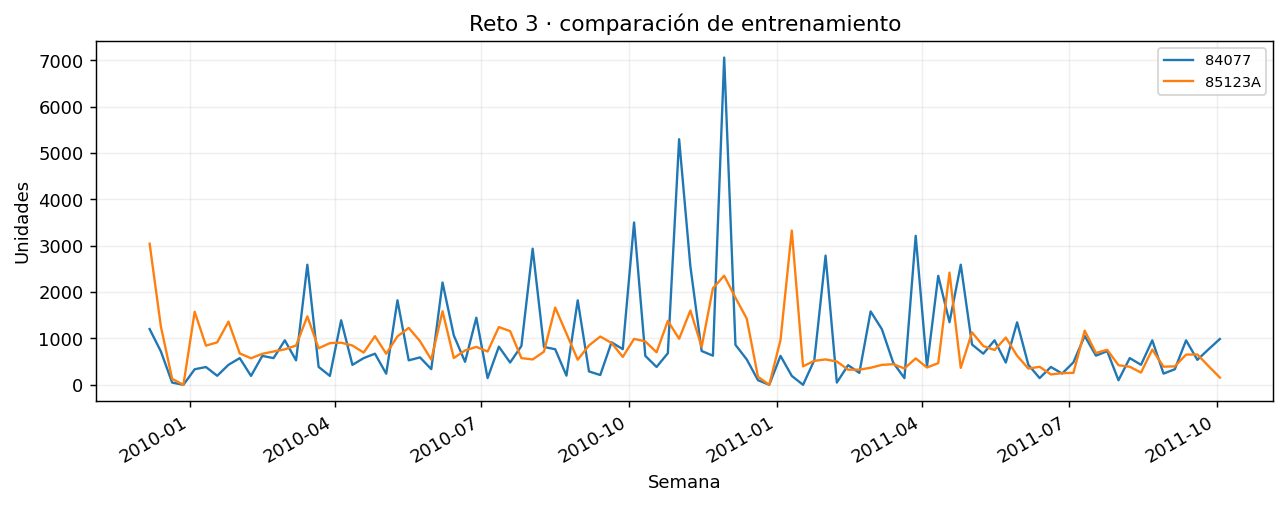

In [79]:
assert len(elegibles)>=2
SKU2=elegibles.loc[1,"StockCode"]
desc2=uk_train.loc[uk_train.StockCode==SKU2,"Description"].dropna().astype(str).mode().iloc[0]
serie2=uk.loc[uk.StockCode==SKU2].groupby("week").Quantity.sum().reindex(semanas,fill_value=0).astype(float)
train2,test2=serie2.loc[semanas_train],serie2.loc[semanas_test]
r3_desc=pd.DataFrame({SKU:train.describe(),SKU2:train2.describe()}).T
r3_desc["semanas_cero"]=[int((train==0).sum()),int((train2==0).sum())]
r3_desc["coef_variacion"]=[train.std()/train.mean(),train2.std()/train2.mean()]
print("Segundo producto:",SKU2,desc2)
display(r3_desc.round(2))
fig=go.Figure()
for cod,y in [(SKU,train),(SKU2,train2)]:fig.add_trace(go.Scatter(x=y.index,y=y.values,name=str(cod)))
fig.update_layout(title="Reto 3 · comparación de entrenamiento",xaxis_title="Semana",yaxis_title="Unidades")
mostrar_figura(fig)


In [80]:
display(Markdown('**Interpretación 3A:**'))
display(Markdown(f"El segundo producto es **{SKU2} · {desc2}**, elegido por su posición en la lista calculada sin test. Su media semanal es **{train2.mean():.1f}**, frente a **{train.mean():.1f}** del primero; su coeficiente de variación es **{train2.std()/train2.mean():.2f}**, frente a **{train.std()/train.mean():.2f}**. Comparar variabilidad relativa ayuda cuando difieren los volúmenes. Las semanas sin ventas no certifican falta de demanda ni continuidad de stock."))


**Interpretación 3A:**

El segundo producto es **85123A · WHITE HANGING HEART T-LIGHT HOLDER**, elegido por su posición en la lista calculada sin test. Su media semanal es **842.7**, frente a **919.5** del primero; su coeficiente de variación es **0.69**, frente a **1.17**. Comparar variabilidad relativa ayuda cuando difieren los volúmenes. Las semanas sin ventas no certifican falta de demanda ni continuidad de stock.

### Reto 3 · Apartado B — Backtesting y selección con la regla común
Ejecute el mismo backtesting con Naïve, Naïve estacional y Exponential Smoothing (`backtest`), resuma los resultados y seleccione con la regla común. Presente la tabla e indique si la selección se decidió por la tolerancia del 1 %.

In [81]:
filas2,q_bt2=backtest(train2,MODELOS,"reto3")
tabla2=resumir(filas2,"modelo",MODELOS)
SELECCIONADO2=seleccionar(tabla2)
min2=tabla2.costo_prom.min()
candidatos2=tabla2.index[tabla2.costo_prom<=min2*(1+TOLERANCIA)+1e-9].tolist()
display(tabla2.round(2));print("Seleccionado:",SELECCIONADO2,"· candidatos a 1 %:",candidatos2)


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
modelo,,,,,,,,,
Naive,4814.82,3483.34,670.62,656.73,867.66,0.97,14694.0,12131.0,0
SeasonalNaive,3306.84,2147.86,459.32,290.28,665.50,0.67,10023.0,8350.0,1
ExpSmoothing,2591.80,1907.11,475.12,266.42,569.80,0.71,14135.0,4870.0,2


Seleccionado: ExpSmoothing · candidatos a 1 %: ['ExpSmoothing']


In [82]:
display(Markdown('**Interpretación 3B:**'))
display(Markdown(f"Se elige **{SELECCIONADO2}**, con costo medio **£{tabla2.loc[SELECCIONADO2,'costo_prom']:.2f}** y desviación **£{tabla2.loc[SELECCIONADO2,'costo_sd']:.2f}**. {'La tolerancia deja varios candidatos y se aplican los desempates.' if len(candidatos2)>1 else 'Solo un modelo cae dentro del 1 %: la tolerancia no cambia el ganador.'} La elección usa los mismos cinco cortes y costos que el primer SKU."))


**Interpretación 3B:**

Se elige **ExpSmoothing**, con costo medio **£2591.80** y desviación **£1907.11**. Solo un modelo cae dentro del 1 %: la tolerancia no cambia el ganador. La elección usa los mismos cinco cortes y costos que el primer SKU.

### Reto 3 · Apartado C — Evaluar en test y comparar ambos productos
Evalúe en test el modelo seleccionado y Naïve para el segundo producto. Construya una tabla comparativa de ambos productos (sin colchón) con modelo seleccionado, costo de validación, costo de test del seleccionado y de Naïve, ahorro o sobrecosto, folds en que superó a Naïve y resultado de la evaluación, aplicando la regla de adopción de la sección 13.

In [83]:
pred2={m:pronosticar(m,train2,TEST_H,"reto3 test") for m in MODELOS}
metricas2={m:evaluar(test2,q) for m,q in pred2.items()}
bt2=pd.DataFrame(filas2)
def decision_sin_colchon(costo,costo_base,ganados,nfolds):
    if costo>=costo_base:return "No adoptar como sustituto de Naïve"
    return "Adoptar como piloto controlado" if ganados>nfolds/2 else "Mantener en evaluación"
filas_comp=[]
for cod,modelo,tval,bb,metricas in [(SKU,SELECCIONADO,resumen_val,bt,{m:evaluar(test,q) for m,q in cantidades_test.items()}),(SKU2,SELECCIONADO2,tabla2,bt2,metricas2)]:
    cv=bb.pivot(index="fold",columns="modelo",values="costo")
    ganados=int((cv[modelo]<cv["Naive"]).sum())
    a,b=metricas[modelo]["costo"],metricas["Naive"]["costo"]
    filas_comp.append({"SKU":cod,"modelo":modelo,"costo_validacion":tval.loc[modelo,"costo_prom"],"costo_test":a,"costo_Naive":b,"ahorro":b-a,"ahorro_pct":100*(b-a)/b if b>0 else np.nan,"folds_ganados":ganados,"decision":decision_sin_colchon(a,b,ganados,len(origenes))})
comparacion=pd.DataFrame(filas_comp).set_index("SKU")
display(comparacion.round(2))
assert len(train2)==96 and len(test2)==8


,modelo,costo_validacion,costo_test,costo_Naive,ahorro,ahorro_pct,folds_ganados,decision
SKU,,,,,,,,
84077,ExpSmoothing,4324.1,8957.6,7087.9,-1869.7,-26.38,4,No adoptar como sustituto de Naïve
85123A,ExpSmoothing,2591.8,3432.0,6640.7,3208.7,48.32,5,Adoptar como piloto controlado


In [84]:
display(Markdown('**Interpretación 3C:**'))
for cod,r in comparacion.iterrows():
    display(Markdown(f"- **SKU {cod}:** {r.modelo}, costo test **£{r.costo_test:.2f}** frente a **£{r.costo_Naive:.2f}**, diferencia a favor del seleccionado **£{r.ahorro:.2f}** (**{r.ahorro_pct:.2f} %**; negativa = sobrecosto), gana **{int(r.folds_ganados)}/{len(origenes)}** folds. Resultado: **{r.decision}**."))
display(Markdown("Esta tabla compara modelos sin colchón en ambos productos. Se mantiene separada de la decisión principal, que evalúa la política seleccionada del primer producto."))


**Interpretación 3C:**

- **SKU 84077:** ExpSmoothing, costo test **£8957.60** frente a **£7087.90**, diferencia a favor del seleccionado **£-1869.70** (**-26.38 %**; negativa = sobrecosto), gana **4/5** folds. Resultado: **No adoptar como sustituto de Naïve**.

- **SKU 85123A:** ExpSmoothing, costo test **£3432.00** frente a **£6640.70**, diferencia a favor del seleccionado **£3208.70** (**48.32 %**; negativa = sobrecosto), gana **5/5** folds. Resultado: **Adoptar como piloto controlado**.

Esta tabla compara modelos sin colchón en ambos productos. Se mantiene separada de la decisión principal, que evalúa la política seleccionada del primer producto.

### Reto 3 · Apartado D — Recomendación consolidada
Prepare una recomendación para la empresa: qué haría con cada producto (adoptar, mantener en evaluación o no adoptar), qué evidencia la respalda y por qué dos productos no permiten generalizar el método a toda la cartera.

**Decisión 3D:**
Para el SKU 84077 conservaría Naïve como referencia y no sustituiría su planificación por Exponential Smoothing: este último costó £1.869,70 más en el test, aunque ganó cuatro de cinco folds de validación.

Para el SKU 85123A propondría un piloto controlado de Exponential Smoothing sin colchón: ahorró £3.264,30 frente a Naïve en el test y ganó los cinco folds. El piloto debería medir disponibilidad, faltantes, excedentes y costos reales durante semanas nuevas.

Dos productos de alta rotación no representan toda la cartera. No extendería automáticamente esta solución a artículos nuevos o intermitentes; comprobaría más SKU y periodos con las mismas reglas antes de ampliarla.

### Revisión de advertencias y verificaciones automáticas

Se resumen las advertencias de **todos** los ajustes de Exponential Smoothing (backtesting, calibración, test, reentrenamiento final y retos) y se comprueban las condiciones de validez del flujo.

In [85]:
aj = pd.DataFrame(registro_ajustes)
display(aj.groupby("etapa").agg(ajustes=("ajuste", "count"), con_advertencias=("advertencias", lambda s: int((s > 0).sum())),
                                tipos=("tipos", lambda s: "; ".join(sorted({t for x in s for t in x.split("; ") if t}))))
          .sort_values("ajustes", ascending=False))
mensajes = sorted({m for x in aj["mensajes"] for m in x.split(" | ") if m})
print("Mensajes distintos:", mensajes if mensajes else "ninguno")
print("Especificaciones usadas:", aj["especificacion"].value_counts().to_dict())

verificaciones = {
    "Ningún fold invade el test": all(train.index[o + BT_H - 1] < semanas_test[0] for o in origenes),
    "Colchón de cada fold calibrado solo con semanas anteriores a su origen": bool((pol_folds["ultima_semana_calibracion"] < pol_folds["inicio_validacion"]).all()),
    "Colchón del test calculado solo con el entrenamiento": len(train) == len(semanas_train) and train.index[-1] < semanas_test[0],
    "La tabla final usa el multiplicador fijado": COLCHON_FINAL == colchon(MULT, MAE_FINAL),
    "El costo de la política en test se recalcula con su colchón": np.isclose(costo_pol, evaluar(test, q_politica)["costo"]),
}
for k, v in verificaciones.items():
    print(("OK   " if v else "FALLA"), k)

,ajustes,con_advertencias,tipos
etapa,,,
reto2,22,0,
sensibilidad ventana 3,15,0,
calibración,10,0,
sensibilidad ventana 2,10,0,
sensibilidad ventana 1,5,0,
reto3,5,0,
backtesting,5,0,
calibración final,2,0,
calibración test,2,0,


Mensajes distintos: ninguno
Especificaciones usadas: {'nivel + tendencia + estacionalidad aditivas (m = 4)': 79}
OK    Ningún fold invade el test
OK    Colchón de cada fold calibrado solo con semanas anteriores a su origen
OK    Colchón del test calculado solo con el entrenamiento
OK    La tabla final usa el multiplicador fijado
OK    El costo de la política en test se recalcula con su colchón


### Retroalimentación final

**Pregunta 10.** Indique dos razones por las que el modelo podría fallar en producción aun cuando el backtesting haya sido bueno.

**Respuesta:**

Primero, las ventas futuras pueden cambiar por campañas, pedidos grandes o cambios de clientes que una serie univariante no anticipa. Segundo, las ventas registradas pueden ocultar demanda no satisfecha por quiebres de stock; además, los costos supuestos pueden diferir de los costos reales. Un backtest favorable no corrige esos límites ni garantiza que el ahorro se repita.


# 15. Ticket de salida

Se seleccionó Exponential Smoothing sin colchón, con costo promedio de validación de £4.372,36. Sin embargo, en test costó £8.957,60 frente a £7.087,90 de Naïve: un sobrecosto de £1.869,70 (26,38 %). Por eso no lo adoptaría como sustituto de Naïve para este producto, aunque ganó cuatro de cinco folds. La proyección posterior de 9.291 unidades es un ejercicio académico; para decidir cuánto comprar faltan las existencias y los pedidos que llegarán a tiempo.

# 16. Conclusiones

1. Se reservaron ocho semanas para test y se compararon los modelos en cinco folds anteriores. Exponential Smoothing obtuvo el menor costo promedio de validación, aunque Naïve tuvo menor MAE. Con costos distintos para excedentes y faltantes, el modelo con menor error no necesariamente es el más conveniente.
2. En el primer producto no sustituiría Naïve: Exponential Smoothing costó un 26,38 % más en test. Haber ganado cuatro de cinco folds no fue suficiente para sostener la ventaja en el periodo final.
3. En el segundo producto, Exponential Smoothing ahorró £3.264,30 (49,16 %) y ganó los cinco folds. Propondría un piloto para ese SKU, sin extender la recomendación a toda la cartera. Son costos simulados y solo ocho semanas de test; además, las ventas registradas no permiten conocer la demanda perdida por falta de stock.

# 17. Evidencia de entrega

- [x] Fuente, hojas, dimensiones, rango de fechas y versiones visibles.
- [x] Limpieza documentada (incluidos `StockCode` nulos).
- [x] Semanas de lunes a domingo; semanas incompletas excluidas.
- [x] Test de 8 semanas reservado antes de seleccionar el SKU, el modelo y la política.
- [x] SKU seleccionado con criterios previos al test y límites del criterio de disponibilidad explicados.
- [x] Exploración solo con entrenamiento.
- [x] Backtesting de 8 semanas con fechas de cada fold y comprobación de que no invade el test.
- [x] Regla única de selección aplicada a modelo, política y retos.
- [x] Colchón calibrado solo con errores previos a cada origen.
- [x] Política fijada antes del test y evaluada una vez.
- [x] Decisión de adopción separada de la proyección académica.
- [x] Tres retos individuales con sus apartados A, B, C y D resueltos e interpretados; advertencias revisadas.
- [ ] Notebook en GitHub (`semana10/`) y en su propio Colab; ambos URLs presentados en la actividad de la semana.
- [x] Uso de IA declarado.

# Referencias
- Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts.
- Sharda, R., Delen, D., & Turban, E. *Business Intelligence, Analytics, Data Science and AI*. Pearson.

La ejecución local no acredita el trabajo desarrollado durante la sesión. Antes de presentar la evidencia corresponde revisar el contenido y comprobar el acceso a los dos enlaces.


In [86]:
assert len(train)==96 and len(test)==8 and len(origenes)==5
assert all(verificaciones.values())
assert not pol_folds.isna().any().any()
assert np.isclose(evaluar(test,q_politica)["costo"],costo_pol)
from pathlib import Path
salida=Path("resultados");salida.mkdir(exist_ok=True)
for nombre,tabla in {"validacion_modelos":resumen_val,"validacion_politicas":resumen_pol,"test":res_test,"plan_academico":plan,"reto1_validacion":tabla_r1b,"reto1_test":tabla_r1c,"reto2_politicas":r2_resumen,"reto2_test":tabla_r2c,"reto3_comparacion":comparacion}.items():
    tabla.to_csv(salida/(nombre+".csv"),index=True)
print("Controles finales aprobados. Tablas guardadas en resultados/.")


Controles finales aprobados. Tablas guardadas en resultados/.
